<div align="center">

[🇪🇸 Español](compra_genetica_es.ipynb) · **🇬🇧 English**

# 🧬🛒 Genetic Shopping
### Shopping-route optimization with Genetic Algorithms

![Python](https://img.shields.io/badge/Python-3.12-3776AB?logo=python&logoColor=white)
![NumPy](https://img.shields.io/badge/NumPy-vectorized-013243?logo=numpy)
![Tests](https://img.shields.io/badge/tests-pytest-0A9EDC?logo=pytest)
![CUDA](https://img.shields.io/badge/GPU-CUDA%20experiment-76B900?logo=nvidia)

</div>

**Problem:** I have a shopping list and several supermarket branches. Each branch sells different
products at different prices and sits at some distance from my home and from the others.
**Where should I buy each product, and in what order should I visit the stores, to spend the least**
(product prices + fuel)?

This notebook builds the solution **step by step**: every cell does *one* thing and shows its result.

| # | Section | # | Section |
|---|---|---|---|
| 1 | Environment setup | 10 | Step-by-step mathematical walkthrough |
| 2 | Data exploration | 11 | Genetic operators (one per cell) |
| 3 | Price matrix | 12 | The `GeneticShoppingOptimizer` class |
| 4 | Graph → Floyd-Warshall | 13 | Running one problem |
| 5 | Mathematical formulation | 14 | Baselines and exact optimum |
| 6 | Gene syntax | 15 | Validation on the 136 problems |
| 7 | Route heuristic (TSP) | 16 | Operator benchmark |
| 8 | Fitness function | 17 | Hyperparameters and scalability |
| 9 | Cost-model validation | 18 | CPU vs GPU experiment · 19 Conclusions · 20 Manual |

## 1. Environment setup
Imports, a fixed seed and hardware detection. The seed is there because a GA is random by nature: without it every run
would give different numbers and we couldn't compare techniques or repeat a result. We print the hardware because the
timings further down only make sense if you know which machine produced them.

In [1]:
LANG = "en"

import ast
import inspect
import os
import platform
import re
import time
import tracemalloc
import warnings
from dataclasses import dataclass, field
from functools import partial
from itertools import combinations
from pathlib import Path
from typing import Iterable

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# Categorical palette in a fixed order (colorblind-validated)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "axes.titleweight": "bold", "lines.linewidth": 2,
})

DATA_DIR = Path("..") / "data"
RESULTS_DIR = Path("..") / "results"
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_JOBS = os.cpu_count()


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}_{LANG}.png", bbox_inches="tight", dpi=130)


# False: heavy experiments (validation, benchmarks) are loaded from results/ when they exist.
# True: everything is recomputed from scratch (~15 min using every core).
RECOMPUTE = os.environ.get("COMPRA_RECOMPUTE", "0") == "1"


def cached(name, compute, parallel=True):
    path = RESULTS_DIR / f"{name}.csv"
    if path.exists() and not RECOMPUTE:
        print(f"📂 Loaded from results/{name}.csv  (RECOMPUTE = True to recompute)")
        return pd.read_csv(path)
    t0 = time.perf_counter()
    df = compute()
    df.to_csv(path, index=False)
    workers = f"{N_JOBS} processes" if parallel else "1 process (sequential)"
    print(f"⚙️ {name}: {len(df)} rows in {time.perf_counter() - t0:.1f} s using {workers}")
    return df


try:
    import torch
    GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except ImportError:
    torch, GPU = None, None

print(f"Python      {platform.python_version()}")
print(f"NumPy       {np.__version__} | pandas {pd.__version__} | networkx {nx.__version__}")
print(f"CPU         {platform.processor()} | {N_JOBS} logical threads")
print(f"GPU         {GPU or 'not available'}")

Python      3.12.5
NumPy       2.2.6 | pandas 2.3.3 | networkx 3.6.1
CPU         AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD | 24 logical threads
GPU         NVIDIA GeForce RTX 4080 SUPER


## 2. Data exploration

### 2.1 The validation dataset (`problemset.xlsx`)
Each row is a problem: a catalog, a fuel price and a shopping list, together with the solutions
of four reference algorithms:

| Prefix | Reference algorithm |
|---|---|
| `qbf` | quasi brute force |
| `ga` | genetic algorithm |
| `gc` | greedy: cheapest |
| `gn` | greedy: nearest |

The `catalog` column points to `problemset/in/...`, but in this repo the files live in
`data/in/`. We fix the path and turn `query` from text into a Python list.

In [2]:
def resolve_catalog_path(catalog: str, data_dir: str | Path) -> Path:
    """The problemset stores paths like 'problemset/in/X.xlsx'; the files live in data/in/."""
    return Path(data_dir) / "in" / Path(catalog).name


def load_problemset(data_dir: str | Path) -> pd.DataFrame:
    """Read problemset.xlsx, parse the query lists and fix the catalog paths."""
    df = pd.read_excel(Path(data_dir) / "problemset.xlsx")
    df["query"] = df["query"].apply(ast.literal_eval)
    df["catalog_path"] = df["catalog"].apply(lambda c: resolve_catalog_path(c, data_dir))
    value_cols = [c for c in df.columns if c.endswith("best value")]
    df["best_known"] = df[value_cols].min(axis=1)
    return df


problemset = load_problemset(DATA_DIR)
print("Shape:", problemset.shape)
problemset[["problem_cluster", "fuel_price", "query", "qbf best value", "ga best value",
            "gc best value", "gn best value", "best_known"]].head()

Shape:

 (136, 14)


,problem_cluster,fuel_price,query,qbf best value,ga best value,gc best value,gn best value,best_known
0,small-3s-4p-f1_10-q1_4-random,1,[Purificadores de aire],"4,401.99","4,401.99","4,401.99","4,401.99","4,401.99"
1,small-3s-4p-f1_10-q1_4-random,1,"[Purificadores de aire, Aceite de girasol, Pas...","11,270.96","11,283.96","11,270.96","12,817.96","11,270.96"
2,small-3s-4p-f1_10-q1_4-random,6,[Purificadores de aire],"4,501.99","4,501.99","4,501.99","4,501.99","4,501.99"
3,small-3s-4p-f1_10-q1_4-random,6,"[Purificadores de aire, Pasta de dientes, Acei...","11,400.96","11,478.96","11,400.96","12,917.96","11,400.96"
4,small-5s-10p-f0_10-q1_10-random,0,[Televisores],619.99,619.99,619.99,"3,638.99",619.99


**How many problems of each kind, and what is missing?** The cluster name encodes the size:
`small-5s-10p-f0_10-q1_10` = 5 stores, 10 products, fuel between 0 and 10 and lists of 1 to 10
products. `best_known` is the best value among the four references.

In [3]:
problemset["k"] = problemset["query"].apply(len)
overview = problemset.groupby("problem_cluster").agg(
    problems=("k", "size"),
    k_min=("k", "min"), k_max=("k", "max"),
    fuel_min=("fuel_price", "min"), fuel_max=("fuel_price", "max"),
    qbf_NaN=("qbf best value", lambda s: s.isna().sum()),
    ga_NaN=("ga best value", lambda s: s.isna().sum()),
)
display(overview)
print("Missing values per column:")
print(problemset.isna().sum()[lambda s: s > 0].to_string())

,problems,k_min,k_max,fuel_min,fuel_max,qbf_NaN,ga_NaN
problem_cluster,,,,,,,
big-100s-300p-f0_10-q1_20-random,12,1,16,1,9,12,0
medium-20s-50p-f0_10-q1_20-random,12,1,16,1,9,12,0
medium-30s-80p-f0_10-q1_20-random,12,1,16,1,9,12,0
small-3s-4p-f1_10-q1_4-random,4,1,4,1,6,0,0
small-5s-10p-f0_10-q1_10-jumbocheap,16,1,10,0,9,0,0
small-5s-10p-f0_10-q1_10-parque,16,1,10,0,9,0,0
small-5s-10p-f0_10-q1_10-punico,16,1,10,0,9,1,3
small-5s-10p-f0_10-q1_10-random,16,1,10,0,9,0,0
small-5s-10p-f0_10-q1_10-same_dist,16,1,10,0,9,0,0


Missing values per column:
qbf best solution    37
qbf best value       37
ga best value         3


### 2.2 Inside a catalog
Each Excel file has two sheets: **`catalogo`** (store, product, price) and **`grafo`**
(source, target, distance). We start with the smallest problem (3 stores, 4 products) because every number can still be
checked by hand there; it is the same one we use later for the step-by-step walkthrough.

In [4]:
def load_catalog(path: str | Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Read the two sheets of a catalog file: product catalog and graph edges."""
    catalog = pd.read_excel(path, sheet_name=0)
    graph = pd.read_excel(path, sheet_name=1)
    catalog.columns = ["store", "product", "price"]
    graph.columns = ["source", "target", "distance"]
    return catalog, graph


SMALL = DATA_DIR / "in" / "small-3s-4p-f1_10-q1_4-random_catalog.xlsx"
catalog_df, graph_df = load_catalog(SMALL)
display(catalog_df.sort_values(["store", "product"]).reset_index(drop=True))
display(graph_df)

,store,product,price
0,Jumbo,Aceite de girasol,"2,689.99"
1,Jumbo,Alfombras,"1,998.99"
2,Jumbo,Pasta de dientes,"2,897.99"
3,Jumbo,Purificadores de aire,"4,724.99"
4,La Sirena,Aceite de girasol,"3,975.99"
5,La Sirena,Alfombras,"3,693.99"
6,La Sirena,Pasta de dientes,"4,175.99"
7,La Sirena,Purificadores de aire,"4,783.99"
8,Supermercado Nacional,Aceite de girasol,"4,116.99"
9,Supermercado Nacional,Alfombras,"1,274.99"


,source,target,distance
0,Jumbo,Jumbo,4
1,Jumbo,Supermercado Nacional,4
2,La Sirena,Supermercado Nacional,16
3,Jumbo,La Sirena,18
4,Supermercado Nacional,Jumbo,15
5,Casa,La Sirena,11
6,Casa,Supermercado Nacional,5
7,Casa,Casa,1
8,La Sirena,Jumbo,1
9,Jumbo,Casa,18


**Important observations about the graph:**
- There are edges `A → B` **and** `B → A` with different distances (`Casa → Supermercado Nacional = 5`
  but `Supermercado Nacional → Casa = 15`). The graph is **directed**, like one-way streets.
- There are self-loops (`Casa → Casa = 1`). Staying in place costs nothing, so we ignore them.

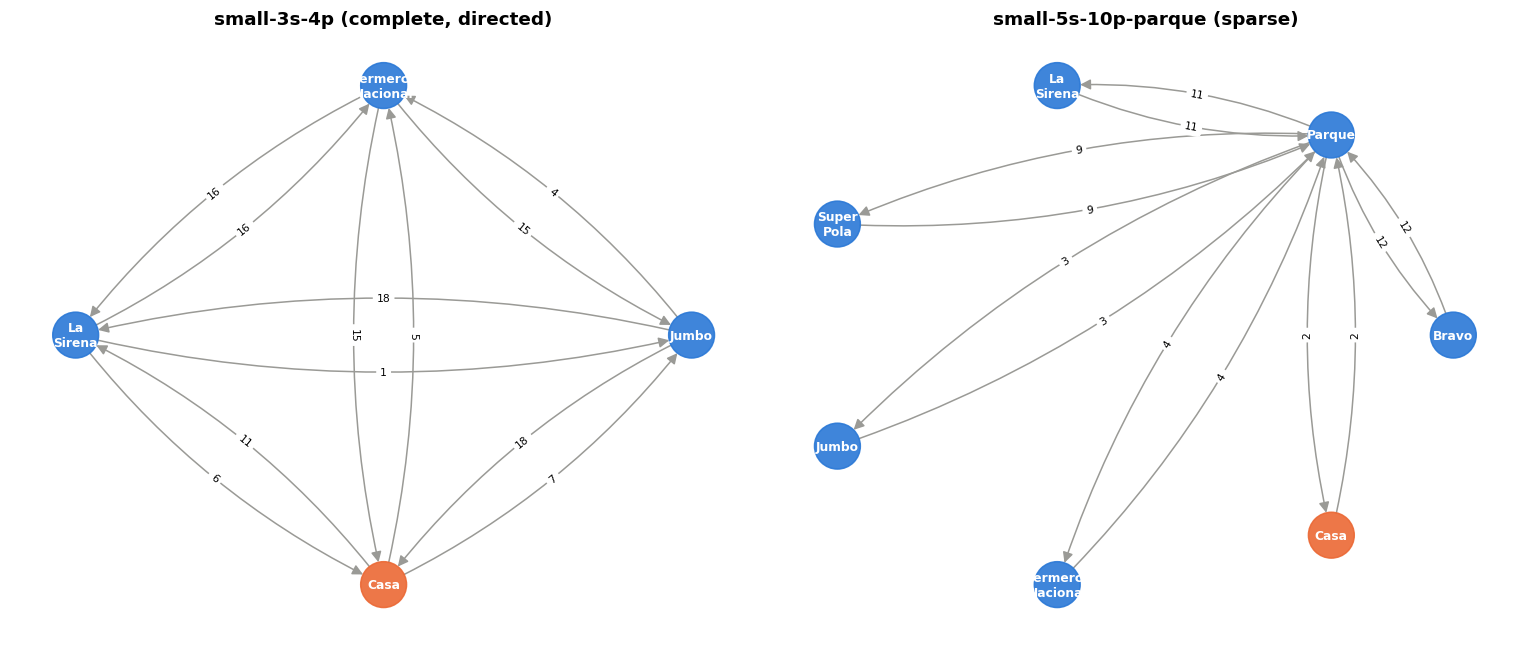

In [5]:
def draw_graph(graph, ax, title, highlight=None):
    G = nx.DiGraph()
    for a, b, d in graph.itertuples(index=False):
        if a != b:
            G.add_edge(a, b, weight=d)
    pos = nx.circular_layout(G)
    colors = [PALETTE[1] if n == "Casa" else PALETTE[0] for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=900, alpha=0.9)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white", font_weight="bold",
                            labels={n: n.replace(" ", "\n") for n in G.nodes})
    edge_colors = [PALETTE[7] if highlight and (u, v) in highlight else "#9a9a96" for u, v in G.edges]
    widths = [3 if highlight and (u, v) in highlight else 1 for u, v in G.edges]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=widths, arrowsize=14,
                           connectionstyle="arc3,rad=0.12", node_size=900)
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=7, connectionstyle="arc3,rad=0.12",
                                 edge_labels={(u, v): int(d["weight"]) for u, v, d in G.edges(data=True)})
    ax.set_title(title)
    ax.axis("off")


PARQUE = DATA_DIR / "in" / "small-5s-10p-f0_10-q1_10-parque_catalog.xlsx"
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_graph(graph_df, axes[0], "small-3s-4p (complete, directed)")
draw_graph(load_catalog(PARQUE)[1], axes[1], "small-5s-10p-parque (sparse)")
plt.tight_layout()
save_fig(fig, "graphs")
plt.show()

The **`parque`** catalog has a **`Parque`** node that is not a store, and the graph is not complete:
to go from one store to another you must pass through intermediate nodes. That is why we later turn
it into a **fully connected** graph with Floyd-Warshall.

### 2.3 Size of every catalog

In [6]:
rows = []
for path in sorted((DATA_DIR / "in").glob("*.xlsx")):
    cat, gr = load_catalog(path)
    n_stores, n_products = cat["store"].nunique(), cat["product"].nunique()
    nodes = set(gr["source"]) | set(gr["target"])
    rows.append({
        "catalog": path.stem.replace("_catalog", ""),
        "stores": n_stores, "products": n_products,
        "catalog_rows": len(cat),
        "density_%": 100 * len(cat) / (n_stores * n_products),
        "nodes": len(nodes), "edges": len(gr),
        "price_min": cat["price"].min(),
        "price_max": cat["price"].max(),
        "dist_max": gr["distance"].max(),
    })
catalog_sizes = pd.DataFrame(rows).set_index("catalog")
catalog_sizes

,stores,products,catalog_rows,density_%,nodes,edges,price_min,price_max,dist_max
catalog,,,,,,,,,
big-100s-300p-f0_10-q1_20-random,100,300,25000,83.33,101,9201,100.99,"4,999.99",19
medium-20s-50p-f0_10-q1_20-random,20,50,800,80.00,21,241,104.99,"4,959.99",19
medium-30s-80p-f0_10-q1_20-random,30,80,1900,79.17,31,461,100.99,"4,995.99",19
small-3s-4p-f1_10-q1_4-random,3,4,12,100.00,4,16,"1,274.99","4,783.99",18
small-5s-10p-f0_10-q1_10-jumbocheap,5,10,40,80.00,6,31,139.99,"4,995.99",19
small-5s-10p-f0_10-q1_10-parque,5,10,40,80.00,7,12,136.99,"4,835.99",12
small-5s-10p-f0_10-q1_10-punico,5,10,21,42.00,6,31,563.99,"4,714.99",19
small-5s-10p-f0_10-q1_10-random,5,10,40,80.00,6,31,212.99,"4,926.99",18
small-5s-10p-f0_10-q1_10-same_dist,5,10,40,80.00,6,31,173.99,"4,866.99",10


💡 **Key fact to understand the results:** prices range from hundreds to thousands, while transport
costs `fuel (0–9) × distance (tens)`. **Product prices dominate the total cost.** That is why the
"buy where it is cheapest" strategy is already very good, and the value of the GA lies in deciding
when it pays to spend a bit more on a product to save a trip.

## 3. Price matrix
We pivot the `catalogo` sheet (long format) into a **stores × products matrix**. When a store does not
sell a product its price is `∞`, so the product is never assigned to it.

Why a matrix instead of the table? Because the GA looks up prices thousands of times per second, and with a NumPy matrix
the price of a whole chromosome is a single vectorized operation. We use `∞` instead of `NaN` because `min` and `argmin`
naturally treat it as "the worst possible option".

Shape: (5, 10) | cells not sold (∞): 29


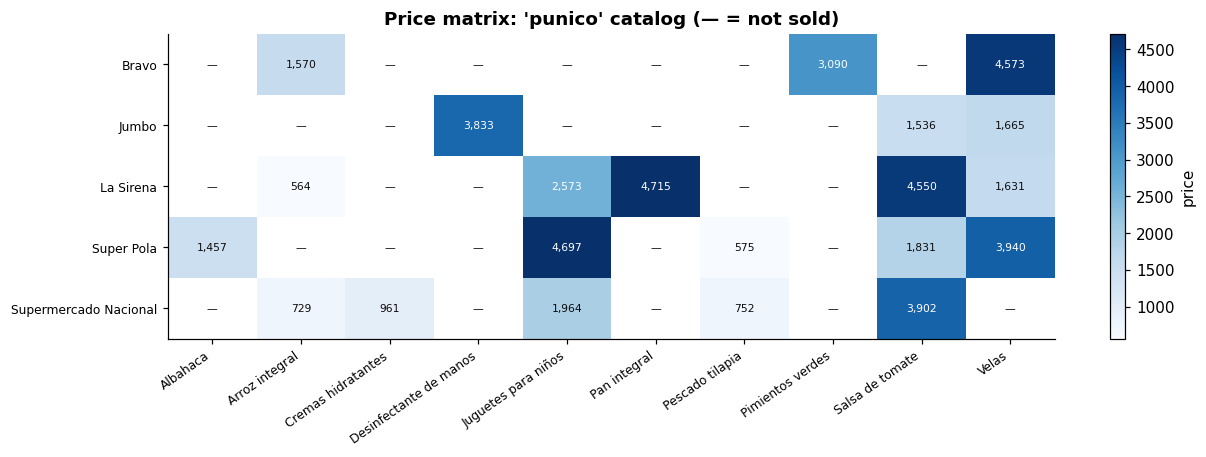

In [7]:
def build_price_matrix(catalog: pd.DataFrame) -> tuple[list[str], list[str], np.ndarray]:
    """Pivot the catalog into a stores x products matrix (np.inf = not sold)."""
    stores = sorted(catalog["store"].unique())
    products = sorted(catalog["product"].unique())
    table = catalog.pivot_table(index="store", columns="product", values="price", aggfunc="min")
    price = table.reindex(index=stores, columns=products).to_numpy(dtype=float)
    price[np.isnan(price)] = np.inf
    return stores, products, price


RANDOM5 = DATA_DIR / "in" / "small-5s-10p-f0_10-q1_10-punico_catalog.xlsx"
stores_, products_, price_ = build_price_matrix(load_catalog(RANDOM5)[0])
print("Shape:", price_.shape, "| cells not sold (∞):", np.isinf(price_).sum())

fig, ax = plt.subplots(figsize=(13, 3.6))
shown = np.where(np.isinf(price_), np.nan, price_)
im = ax.imshow(shown, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(products_)), products_, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(stores_)), stores_, fontsize=8)
ax.grid(False)
for i in range(shown.shape[0]):
    for j in range(shown.shape[1]):
        txt = "—" if np.isnan(shown[i, j]) else f"{shown[i, j]:,.0f}"
        dark = not np.isnan(shown[i, j]) and shown[i, j] > np.nanmean(shown)
        ax.text(j, i, txt, ha="center", va="center", fontsize=7, color="white" if dark else "#0b0b0b")
ax.set_title("Price matrix: 'punico' catalog (— = not sold)")
fig.colorbar(im, ax=ax, label="price")
save_fig(fig, "price_matrix")
plt.show()

## 4. From graph to distance matrix

### 4.1 Adjacency matrix (directed)
`A[i, j]` is the length of edge `i → j`, or `∞` if there is no edge. The diagonal is 0 and self-loops
are ignored. If an edge appears twice we keep the shorter one.

The matrix is directed (we don't copy `A[i, j]` into `A[j, i]`) because of what we saw in the graph: going and coming back
can have different lengths. In section 9 we check with data that this was the right call.

In [8]:
HOME = "Casa"


def build_adjacency(graph: pd.DataFrame, nodes: list[str], directed: bool = True) -> np.ndarray:
    """Adjacency matrix with np.inf where there is no edge.

    Self-loops are ignored (staying in the same place costs 0) and repeated
    edges keep the shortest one.
    """
    idx = {name: i for i, name in enumerate(nodes)}
    A = np.full((len(nodes), len(nodes)), np.inf)
    np.fill_diagonal(A, 0.0)
    for a, b, d in graph.itertuples(index=False):
        if a == b:
            continue
        i, j = idx[a], idx[b]
        A[i, j] = min(A[i, j], d)
        if not directed:
            A[j, i] = min(A[j, i], d)
    return A


parque_graph = load_catalog(PARQUE)[1]
parque_nodes = sorted(set(parque_graph["source"]) | set(parque_graph["target"]))
A = build_adjacency(parque_graph, parque_nodes)
print("Pairs (i, j) without a direct edge:", np.isinf(A).sum())
pd.DataFrame(A, index=parque_nodes, columns=parque_nodes)

Pairs (i, j) without a direct edge: 30


,Bravo,Casa,Jumbo,La Sirena,Parque,Super Pola,Supermercado Nacional
Bravo,0.00,inf,inf,inf,12.00,inf,inf
Casa,inf,0.00,inf,inf,2.00,inf,inf
Jumbo,inf,inf,0.00,inf,3.00,inf,inf
La Sirena,inf,inf,inf,0.00,11.00,inf,inf
Parque,12.00,2.00,3.00,11.00,0.00,9.00,4.00
Super Pola,inf,inf,inf,inf,9.00,0.00,inf
Supermercado Nacional,inf,inf,inf,inf,4.00,inf,0.00


### 4.2 Floyd-Warshall: a fully connected graph
The GA needs to know what it costs to go from any store to any other, even without a direct street. So we turn the
graph into a **fully connected** one where every pair of nodes holds its shortest distance. Floyd-Warshall tries every
node $k$ as an intermediate stop:

$$D^{(k)}_{ij} = \min\left(D^{(k-1)}_{ij},\; D^{(k-1)}_{ik} + D^{(k-1)}_{kj}\right)$$

Complexity $O(n^3)$. With NumPy the double loop over $(i, j)$ is vectorized via broadcasting, so only
the loop over $k$ remains.

In [9]:
def floyd_warshall(A: np.ndarray) -> np.ndarray:
    """All-pairs shortest paths. Turns any connected graph into a complete one.

    D[i, j] = min(D[i, j], D[i, k] + D[k, j]) for every intermediate node k,
    vectorized over (i, j) with NumPy broadcasting.
    """
    D = A.copy()
    for k in range(len(D)):
        D = np.minimum(D, D[:, [k]] + D[[k], :])
    return D


D_parque = floyd_warshall(A)
print("Unconnected pairs after Floyd-Warshall:", np.isinf(D_parque).sum())

# Check against networkx's Dijkstra
G = nx.DiGraph()
for a, b, d in parque_graph.itertuples(index=False):
    if a != b:
        G.add_edge(a, b, weight=min(d, G[a][b]["weight"]) if G.has_edge(a, b) else d)
nx_dist = dict(nx.all_pairs_dijkstra_path_length(G))
same = all(D_parque[i, j] == nx_dist[a][b] for i, a in enumerate(parque_nodes) for j, b in enumerate(parque_nodes))
print("Matches networkx?", "✅" if same else "❌")
pd.DataFrame(D_parque, index=parque_nodes, columns=parque_nodes)

Unconnected pairs after Floyd-Warshall: 0
Matches networkx? ✅


,Bravo,Casa,Jumbo,La Sirena,Parque,Super Pola,Supermercado Nacional
Bravo,0.00,14.00,15.00,23.00,12.00,21.00,16.00
Casa,14.00,0.00,5.00,13.00,2.00,11.00,6.00
Jumbo,15.00,5.00,0.00,14.00,3.00,12.00,7.00
La Sirena,23.00,13.00,14.00,0.00,11.00,20.00,15.00
Parque,12.00,2.00,3.00,11.00,0.00,9.00,4.00
Super Pola,21.00,11.00,12.00,20.00,9.00,0.00,13.00
Supermercado Nacional,16.00,6.00,7.00,15.00,4.00,13.00,0.00


### 4.3 The full problem instance
We bundle everything into a `ShoppingInstance`. The GA only cares about the home and the stores, so we
shrink the matrix to those points: **point 0 is the home and point `s + 1` is store `s`**.
Intermediate nodes (like `Parque`) are already "absorbed" into the shortest distances.

The reduction is not just cosmetic: with the "point = store + 1" numbering, going from a gene (a store) to a matrix row is
a plain addition, with no dictionary lookups in the part that runs most often.

In [10]:
@dataclass
class ShoppingInstance:
    """Everything the optimizer needs to know about one catalog file.

    Point indexing used by ``D``: point 0 is the home, point ``s + 1`` is store ``s``.
    """
    stores: list[str]          # store names; the index is the gene value
    products: list[str]        # every product that appears in the catalog
    price: np.ndarray          # (n_stores, n_products) price, np.inf when not sold
    nodes: list[str]           # every node of the raw graph (may include non-store nodes)
    node_dist: np.ndarray      # (n_nodes, n_nodes) shortest directed distances
    D: np.ndarray              # (n_stores + 1, n_stores + 1) distances between home and stores
    catalog: pd.DataFrame      # raw "catalogo" sheet
    graph: pd.DataFrame        # raw "grafo" sheet


def load_instance(path: str | Path, directed: bool = True) -> ShoppingInstance:
    """Load a catalog file and precompute prices and shortest-path distances."""
    catalog, graph = load_catalog(path)
    stores, products, price = build_price_matrix(catalog)
    nodes = sorted(set(graph["source"]) | set(graph["target"]) | set(stores) | {HOME})
    node_dist = floyd_warshall(build_adjacency(graph, nodes, directed))
    points = [nodes.index(HOME)] + [nodes.index(s) for s in stores]
    D = node_dist[np.ix_(points, points)]
    return ShoppingInstance(stores, products, price, nodes, node_dist, D, catalog, graph)


inst_small = load_instance(SMALL)
print("Stores:", inst_small.stores)
print("Products:", inst_small.products)
labels = [HOME] + inst_small.stores
pd.DataFrame(inst_small.D, index=labels, columns=labels)

Stores: ['Jumbo', 'La Sirena', 'Supermercado Nacional']
Products: ['Aceite de girasol', 'Alfombras', 'Pasta de dientes', 'Purificadores de aire']


,Casa,Jumbo,La Sirena,Supermercado Nacional
Casa,0.00,7.00,11.00,5.00
Jumbo,18.00,0.00,18.00,4.00
La Sirena,6.00,1.00,0.00,5.00
Supermercado Nacional,15.00,15.00,16.00,0.00


**A hidden detail in the data:** some graphs contain edges of distance **0**. After Floyd-Warshall a zero can
"propagate" and leave many store pairs at distance 0. We measure the fraction of such pairs per catalog:

In [11]:
zero_rows = []
for path in sorted((DATA_DIR / "in").glob("*.xlsx")):
    inst = load_instance(path)
    n = len(inst.D)
    zero_rows.append({"catalog": path.stem.replace("_catalog", ""),
                      "edges with distance 0": int((inst.graph["distance"] == 0).sum()),
                      "% pairs at distance 0 (Floyd)": 100 * ((inst.D == 0).sum() - n) / (n * n - n)})
pd.DataFrame(zero_rows).set_index("catalog")

,edges with distance 0,% pairs at distance 0 (Floyd)
catalog,,
big-100s-300p-f0_10-q1_20-random,457,97.03
medium-20s-50p-f0_10-q1_20-random,8,3.10
medium-30s-80p-f0_10-q1_20-random,25,4.30
small-3s-4p-f1_10-q1_4-random,0,0.00
small-5s-10p-f0_10-q1_10-jumbocheap,1,3.33
small-5s-10p-f0_10-q1_10-parque,0,0.00
small-5s-10p-f0_10-q1_10-punico,1,3.33
small-5s-10p-f0_10-q1_10-random,1,3.33
small-5s-10p-f0_10-q1_10-same_dist,0,0.00


⚠️ In the **`big`** catalog (100 stores) **97 %** of the pairs end up at distance 0: moving between stores is
practically free there, so the problem reduces to "buy each product where it is cheapest". Keep this in mind when
reading that cluster's results.

## 5. Mathematical formulation

**Data**
- $Q = \{1, \dots, k\}$: products in the shopping list.
- $S$: stores, and $A_i \subseteq S$: stores that sell product $i$.
- $c_{s,i}$: price of product $i$ at store $s$.
- $d(u, v)$: shortest directed distance (Floyd-Warshall), with $0$ = home.
- $\varphi$: fuel price per distance unit.

**Decision variable:** $x = (x_1, \dots, x_k)$ with $x_i \in A_i$, the store where product $i$ is bought.
The stores to visit are $U(x) = \{x_1, \dots, x_k\}$ (no repeats).

**Objective**

$$\min_{x}\; f(x) = \underbrace{\sum_{i=1}^{k} c_{x_i,i}}_{\text{product cost}} \;+\; \varphi \cdot \underbrace{\mathrm{TSP}\big(U(x)\big)}_{\text{route distance}}$$

$$\mathrm{TSP}(U) = \min_{\pi \in \mathrm{Perm}(U)} \Big[d(0, \pi_1) + \sum_{j=1}^{|U|-1} d(\pi_j, \pi_{j+1}) + d(\pi_{|U|}, 0)\Big]$$

It is a **combinatorial, non-differentiable** problem with many local optima, exactly the kind of
problem where genetic algorithms shine. The search space has $\prod_i |A_i|$ assignments, and each
assignment has $|U|!$ possible visiting orders.

In [12]:
instances = {p: load_instance(p) for p in problemset["catalog_path"].unique()}


def search_space_log10(row):
    inst = instances[row.catalog_path]
    cols = [inst.products.index(p) for p in row.query]
    return np.log10(np.isfinite(inst.price[:, cols]).sum(axis=0)).sum()


problemset["log10_space"] = problemset.apply(search_space_log10, axis=1)
problemset.groupby("problem_cluster")["log10_space"].agg(["min", "median", "max"]).rename(
    columns=lambda c: f"log10(assignments) {c}")

,log10(assignments) min,log10(assignments) median,log10(assignments) max
problem_cluster,,,
big-100s-300p-f0_10-q1_20-random,1.90,16.28,30.83
medium-20s-50p-f0_10-q1_20-random,1.11,10.37,19.36
medium-30s-80p-f0_10-q1_20-random,1.36,11.62,22.47
small-3s-4p-f1_10-q1_4-random,0.48,1.19,1.91
small-5s-10p-f0_10-q1_10-jumbocheap,0.48,3.16,5.94
small-5s-10p-f0_10-q1_10-parque,0.48,3.33,5.96
small-5s-10p-f0_10-q1_10-punico,0.00,1.47,2.46
small-5s-10p-f0_10-q1_10-random,0.60,3.29,5.89
small-5s-10p-f0_10-q1_10-same_dist,0.48,3.23,5.96


`big` problems reach $10^{31}$ possible assignments (more than seconds in the age of the universe,
$\approx 4 \times 10^{17}$). Enumerating them is impossible: we need a **metaheuristic**.

## 6. Gene syntax

| GA concept | In this problem |
|---|---|
| **Gene** | integer = index of the store where I buy *one* product |
| **Chromosome** (genotype) | vector of `k` integers, one per product in the list |
| **Valid alleles of gene `i`** | only the stores that sell product `i` ($A_i$) |
| **Phenotype** | the route: stores in visiting order + what to buy at each one |

**Why not put the route order in the chromosome?** Because once we know *which* stores to visit, the best
order can be computed exactly (and fast) with a TSP heuristic. The GA then searches only the space of
assignments and **every chromosome is always valid**: no penalties or repairs needed.

In [13]:
query_small = problemset.loc[1, "query"]
cols = [inst_small.products.index(p) for p in query_small]
allowed = [np.flatnonzero(np.isfinite(inst_small.price[:, c])) for c in cols]

example = np.array([2, 0, 0, 2])  # an example chromosome
pd.DataFrame({
    "gene i": range(len(query_small)),
    "product": query_small,
    "valid alleles": [[inst_small.stores[s] for s in a] for a in allowed],
    "gene value": example,
    "store": [inst_small.stores[s] for s in example],
    "price": [inst_small.price[s, c] for s, c in zip(example, cols)],
})

,gene i,product,valid alleles,gene value,store,price
0,0,Purificadores de aire,"[Jumbo, La Sirena, Supermercado Nacional]",2,Supermercado Nacional,"4,381.99"
1,1,Aceite de girasol,"[Jumbo, La Sirena, Supermercado Nacional]",0,Jumbo,"2,689.99"
2,2,Pasta de dientes,"[Jumbo, La Sirena, Supermercado Nacional]",0,Jumbo,"2,897.99"
3,3,Alfombras,"[Jumbo, La Sirena, Supermercado Nacional]",2,Supermercado Nacional,"1,274.99"


## 7. Route heuristic: in what order do I visit the stores?
Given the set of stores in a chromosome we look for the shortest closed tour `Home → … → Home`.
It is an **asymmetric TSP** (the graph is directed).

### 7.1 Length of a route

In [14]:
def route_length(order: list[int], D: np.ndarray) -> float:
    """Length of the closed route 0 -> order[0] -> ... -> order[-1] -> 0."""
    path = [0, *order, 0]
    return float(D[path[:-1], path[1:]].sum())


order = [3, 1]  # points: 3 = Supermercado Nacional, 1 = Jumbo
print("Casa → Supermercado Nacional → Jumbo → Casa =", route_length(order, inst_small.D))
print("Casa → Jumbo → Supermercado Nacional → Casa =", route_length(order[::-1], inst_small.D))

Casa → Supermercado Nacional → Jumbo → Casa = 38.0
Casa → Jumbo → Supermercado Nacional → Casa = 26.0


Order matters: the same pair of stores costs 38 or 26 depending on the direction.

### 7.2 Held-Karp: exact TSP via dynamic programming
`dp[mask, j]` = shortest path that leaves home, visits exactly the points in `mask` and ends at `j`:

$$dp[mask \cup \{j\}, j] = \min_{k \in mask} \big(dp[mask, k] + d(k, j)\big)$$

It costs $O(2^n n^2)$, perfect for $n \le 9$ distinct stores (the usual case in these routes).

In [15]:
def held_karp(points: list[int], D: np.ndarray) -> tuple[float, list[int]]:
    """Exact TSP by dynamic programming over subsets: O(2^n * n^2).

    dp[mask, j] = shortest path that leaves home, visits exactly the points in
    ``mask`` and ends at point j.
    """
    n = len(points)
    if n == 0:
        return 0.0, []
    sub = D[np.ix_(points, points)]
    full = 1 << n
    dp = np.full((full, n), np.inf)
    parent = np.full((full, n), -1, dtype=int)
    for j in range(n):
        dp[1 << j, j] = D[0, points[j]]
    bits = 1 << np.arange(n)
    for mask in range(1, full):
        cand = dp[mask][:, None] + sub              # cand[k, j]: arrive at j coming from k
        best_k = cand.argmin(axis=0)
        best = cand[best_k, np.arange(n)]
        free = np.flatnonzero((mask & bits) == 0)   # points not visited yet
        new_masks = mask | bits[free]
        better = best[free] < dp[new_masks, free]
        dp[new_masks[better], free[better]] = best[free[better]]
        parent[new_masks[better], free[better]] = best_k[free[better]]
    totals = dp[full - 1] + D[points, 0]
    last = int(totals.argmin())
    order, mask = [], full - 1
    while last != -1:
        order.append(points[last])
        prev = parent[mask, last]
        mask ^= 1 << last
        last = prev
    return float(totals.min()), order[::-1]


length, best_order = held_karp([1, 2, 3], inst_small.D)
print(f"Optimal route visiting all 3 stores: "
      f"Casa → {' → '.join(labels[p] for p in best_order)} → Casa = {length}")

Optimal route visiting all 3 stores: Casa → La Sirena → Jumbo → Supermercado Nacional → Casa = 31.0


### 7.3 Nearest neighbor + 2-opt (for long routes)
With more than 9 stores Held-Karp gets expensive. There we use a constructive heuristic (always go to
the closest store) followed by a **2-opt** local search (reverse segments while it improves).

In [16]:
def nearest_neighbor(points: list[int], D: np.ndarray) -> list[int]:
    """Greedy route: always go to the closest point not visited yet."""
    pending, order, current = set(points), [], 0
    while pending:
        current = min(pending, key=lambda p: D[current, p])
        order.append(current)
        pending.remove(current)
    return order


def two_opt(order: list[int], D: np.ndarray) -> list[int]:
    """Local search: reverse segments while the route gets shorter."""
    best, best_len = list(order), route_length(order, D)
    improved = True
    while improved:
        improved = False
        for i in range(len(best) - 1):
            for j in range(i + 1, len(best)):
                candidate = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                length = route_length(candidate, D)
                if length < best_len - 1e-9:
                    best, best_len, improved = candidate, length, True
    return best


inst_m30 = load_instance(DATA_DIR / "in" / "medium-30s-80p-f0_10-q1_20-random_catalog.xlsx")
points = list(range(1, 13))  # 12 stores
t = time.perf_counter(); nn = nearest_neighbor(points, inst_m30.D); t_nn = time.perf_counter() - t
t = time.perf_counter(); opt = two_opt(nn, inst_m30.D); t_2opt = time.perf_counter() - t
t = time.perf_counter(); hk_len, _ = held_karp(points, inst_m30.D); t_hk = time.perf_counter() - t
pd.DataFrame({
    "method": ["Nearest neighbor", "NN + 2-opt", "Held-Karp (exact)"],
    "length": [route_length(nn, inst_m30.D), route_length(opt, inst_m30.D), hk_len],
    "ms": [1000 * t_nn, 1000 * (t_nn + t_2opt), 1000 * t_hk],
})

,method,length,ms
0,Nearest neighbor,33.00,0.06
1,NN + 2-opt,33.00,0.51
2,Held-Karp (exact),26.00,52.96


### 7.4 `RouteSolver`: method selection + memoization
During evolution many chromosomes share the same **set** of stores. We cache every solved route in a
dictionary keyed by `frozenset`, so each set is computed only once.

In [17]:
class RouteSolver:
    """Finds the visiting order for a set of stores, with memoization.

    Uses Held-Karp (exact) up to ``exact_limit`` stores and nearest neighbor +
    2-opt above that. Stores are given as store indices; point = store + 1.
    """

    def __init__(self, D: np.ndarray, exact_limit: int = 9):
        self.D = D
        self.exact_limit = exact_limit
        self.cache: dict[frozenset, tuple[float, list[int]]] = {}
        self.hits = 0
        self.misses = 0

    def solve(self, stores: Iterable[int]) -> tuple[float, list[int]]:
        key = frozenset(int(s) for s in stores)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        points = sorted(s + 1 for s in key)
        if len(points) <= self.exact_limit:
            length, order = held_karp(points, self.D)
        else:
            order = two_opt(nearest_neighbor(points, self.D), self.D)
            length = route_length(order, self.D)
        result = (length, [p - 1 for p in order])
        self.cache[key] = result
        return result


solver = RouteSolver(inst_small.D)
for stores in [[0, 2], [2, 0], [2, 0, 0, 2], [0, 1, 2]]:
    length, order = solver.solve(stores)
    print(f"{str(stores):14s} → {[inst_small.stores[s] for s in order]} = {length}")
print(f"cache: hits={solver.hits}, misses={solver.misses}")

[0, 2]         → ['Jumbo', 'Supermercado Nacional'] = 26.0
[2, 0]         → ['Jumbo', 'Supermercado Nacional'] = 26.0
[2, 0, 0, 2]   → ['Jumbo', 'Supermercado Nacional'] = 26.0
[0, 1, 2]      → ['La Sirena', 'Jumbo', 'Supermercado Nacional'] = 31.0
cache: hits=2, misses=2


## 8. Fitness function
`ShoppingProblem` ties an instance to a concrete query (list + fuel price). It computes:
- `product_cost`: sum of prices, vectorized with NumPy fancy indexing.
- `transport_cost`: fuel × length of the optimal route for the set of stores.
- `cost` = the **objective function to minimize**.
- `decode` / `format_answer`: turn the genotype into the phenotype (the answer as `RESPUESTA> (store, [products]) -> …`).

We split the cost into products and transport so we can see *where* each saving comes from, and because later it helps
explain why, in this dataset, price matters far more than fuel.

In [18]:
class ShoppingProblem:
    """One shopping query on one catalog.

    Gene syntax: a chromosome is an integer vector of length k (one gene per
    product in the query); gene i is the index of the store where product i is
    bought. Only stores that sell product i are allowed, so every chromosome is
    a valid purchase.
    """

    def __init__(self, instance: ShoppingInstance, query: list[str], fuel_price: float,
                 exact_limit: int = 9):
        missing = [p for p in query if p not in instance.products]
        if missing:
            raise ValueError(f"Products not found in the catalog: {missing}")
        self.instance = instance
        self.query = list(query)
        self.fuel_price = float(fuel_price)
        self.k = len(query)
        cols = [instance.products.index(p) for p in query]
        self.price = instance.price[:, cols]                       # (n_stores, k)
        self.allowed = [np.flatnonzero(np.isfinite(self.price[:, i])) for i in range(self.k)]
        if any(len(a) == 0 for a in self.allowed):
            raise ValueError("Some product is not sold by any store")
        self.router = RouteSolver(instance.D, exact_limit)
        self.evaluations = 0

    def product_cost(self, chromosome: np.ndarray) -> float:
        return float(self.price[chromosome, np.arange(self.k)].sum())

    def transport_cost(self, chromosome: np.ndarray) -> float:
        length, _ = self.router.solve(chromosome)
        return self.fuel_price * length

    def cost(self, chromosome: np.ndarray) -> float:
        """Objective to minimize."""
        self.evaluations += 1
        return self.product_cost(chromosome) + self.transport_cost(chromosome)

    def evaluate(self, population: np.ndarray) -> np.ndarray:
        """Cost of every chromosome in the population (one row per individual)."""
        return np.array([self.cost(ind) for ind in population])

    def decode(self, chromosome: np.ndarray) -> list[tuple[str, list[str]]]:
        """Phenotype: the stores in visiting order with what to buy in each one."""
        _, order = self.router.solve(chromosome)
        stores = self.instance.stores
        return [(stores[s], [self.query[i] for i in range(self.k) if chromosome[i] == s])
                for s in order]

    def format_answer(self, chromosome: np.ndarray) -> str:
        parts = []
        for store, items in self.decode(chromosome):
            parts.append(f"({store}, {items[0]})" if len(items) == 1
                         else f"({store}, [{', '.join(items)}])")
        return "RESPUESTA> " + " -> ".join(parts)


row = problemset.loc[1]
problem_small = ShoppingProblem(inst_small, row.query, row.fuel_price)
print("Chromosome:", example)
print(f"Products  = {problem_small.product_cost(example):,.2f}")
print(f"Transport = {problem_small.transport_cost(example):,.2f}")
print(f"Total      = {problem_small.cost(example):,.2f}")
print(problem_small.format_answer(example))

Chromosome: [2 0 0 2]
Products  = 11,244.96
Transport = 26.00
Total      = 11,270.96
RESPUESTA> (Jumbo, [Aceite de girasol, Pasta de dientes]) -> (Supermercado Nacional, [Purificadores de aire, Alfombras])


## 9. Cost-model validation against 504 reference solutions
Before optimizing we must be **sure we measure cost exactly like the references do**. The dataset holds
4 solutions per problem as `(store, product)` sequences in visiting order. We parse them and recompute
their cost with our model, first assuming a **directed** graph and then an **undirected** one.

In [19]:
_PAIR = re.compile(r"array\(\[(['\"])(.*?)\1, (['\"])(.*?)\3\]")


def parse_solution(text) -> list[tuple[str, str]] | None:
    """Parse the reference solution strings ("[array(['Jumbo', 'Arroz'], ...) ...]")."""
    if not isinstance(text, str):
        return None
    return [(m.group(2), m.group(4)) for m in _PAIR.finditer(text)]


def evaluate_sequence(instance: ShoppingInstance, sequence: list[tuple[str, str]],
                      fuel_price: float) -> float:
    """Cost of an explicit (store, product) sequence visited in the given order.

    Used to check our cost model against the reference solutions.
    """
    s_idx = {s: i for i, s in enumerate(instance.stores)}
    p_idx = {p: i for i, p in enumerate(instance.products)}
    products = sum(instance.price[s_idx[s], p_idx[p]] for s, p in sequence)
    route = [s_idx[s] + 1 for s, _ in sequence]
    return float(products + fuel_price * route_length(route, instance.D))


undirected = {p: load_instance(p, directed=False) for p in instances}
checks = []
for _, r in problemset.iterrows():
    for alg in ["qbf", "ga", "gc", "gn"]:
        sol, value = parse_solution(r[f"{alg} best solution"]), r[f"{alg} best value"]
        if sol is None or np.isnan(value):
            continue
        checks.append({
            "directed": abs(evaluate_sequence(instances[r.catalog_path], sol, r.fuel_price) - value) < 1e-6,
            "undirected": abs(evaluate_sequence(undirected[r.catalog_path], sol, r.fuel_price) - value) < 1e-6,
        })
checks = pd.DataFrame(checks)
print(f"Solutions checked: {len(checks)}")
for col in checks:
    print(f"  {col:12s}: {checks[col].sum():3d} / {len(checks)}  {'✅' if checks[col].all() else '❌'}")

Solutions checked: 504
  directed    : 504 / 504  ✅
  undirected  : 224 / 504  ❌


✅ **The model reproduces all 504 reference solutions to the cent** with a directed graph, closed routes
and Floyd-Warshall. The undirected version does not match, which confirms the streets are one-way.
This cell is the foundation of trust for everything that follows, and it is also automated in
`tests/test_fitness.py`.

## 10. Step-by-step mathematical walkthrough: one generation "by hand"
We take problem 1 (3 stores, 4 products, fuel = 1) and a population of **4 individuals**.
We run one full generation showing every number.

The point is to take the "magic" out of the algorithm: with 4 individuals you can follow every draw and every sum with pen
and paper, and it becomes clear that a GA is nothing more than repeating these steps many times.

### 10.1 Initialization and evaluation

In [20]:
rng_demo = np.random.default_rng(7)
P = problem_small
pop0 = np.array([[rng_demo.choice(a) for a in P.allowed] for _ in range(4)])


def explain(population, problem):
    rows = []
    for idx, ind in enumerate(population):
        length, order = problem.router.solve(ind)
        rows.append({
            "individual": f"x{idx}", "genes": ind.tolist(),
            "route": " → ".join(["Casa", *[problem.instance.stores[s] for s in order], "Casa"]),
            "Σ prices": problem.product_cost(ind), "distance": length,
            "φ·dist": problem.fuel_price * length, "f(x)": problem.product_cost(ind) + problem.fuel_price * length,
        })
    return pd.DataFrame(rows)


print("Products:", P.query, "| φ =", P.fuel_price)
table0 = explain(pop0, P)
table0

Products: ['Purificadores de aire', 'Aceite de girasol', 'Pasta de dientes', 'Alfombras'] | φ = 1.0


,individual,genes,route,Σ prices,distance,φ·dist,f(x)
0,x0,"[2, 1, 2, 2]",Casa → Supermercado Nacional → La Sirena → Casa,"12,656.96",27.00,27.00,"12,683.96"
1,x1,"[1, 2, 2, 0]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"13,923.96",31.00,31.00,"13,954.96"
2,x2,"[0, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,587.96",26.00,26.00,"11,613.96"
3,x3,"[2, 0, 1, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,522.96",31.00,31.00,"12,553.96"


### 10.2 Roulette selection (and why it struggles here)
Since we minimize, we use $\text{fitness}_i = 1/f(x_i)$ and probability
$p_i = \text{fitness}_i / \sum_j \text{fitness}_j$. Then we spin the wheel with random numbers
$r \sim U(0,1)$ over the cumulative probability.

In [21]:
costs0 = table0["f(x)"].to_numpy()
fit = 1 / costs0
roulette = pd.DataFrame({"f(x)": costs0, "1/f(x)": fit, "p_i": fit / fit.sum(),
                         "cumulative": np.cumsum(fit / fit.sum())},
                        index=table0.iloc[:, 0])
display(roulette.style.format({"f(x)": "{:,.2f}", "1/f(x)": "{:.3e}", "p_i": "{:.4f}", "cumulative": "{:.4f}"}))

r = rng_demo.random(4)
picked = np.searchsorted(np.cumsum(fit / fit.sum()), r)
for ri, pi in zip(r, picked):
    print(f"r = {ri:.4f} → x{pi}")

,f(x),1/f(x),p_i,cumulative
individual,,,,
x0,"12,683.96",7.884e-05,0.2493,0.2493
x1,"13,954.96",7.166e-05,0.2266,0.4759
x2,"11,613.96",8.610e-05,0.2723,0.7481
x3,"12,553.96",7.966e-05,0.2519,1.0000


r = 0.7971 → x3
r = 0.4679 → x1
r = 0.3030 → x1
r = 0.2784 → x1


The probabilities come out almost equal (≈ 0.25 each) because the costs differ little *in proportion*.
Roulette exerts almost no **selective pressure**. That is why we also implement **tournament** and
**ranking**, which depend on the *order* of the costs and not on their magnitude.

### 10.3 Tournament selection (k = 2)
Pick `k` individuals at random; the one with the lowest cost wins.

In [22]:
parents = []
for _ in range(4):
    a, b = rng_demo.integers(0, 4, size=2)
    winner = a if costs0[a] <= costs0[b] else b
    parents.append(winner)
    print(f"tournament x{a} ({costs0[a]:,.2f}) vs x{b} ({costs0[b]:,.2f}) → winner x{winner}")

tournament x2 (11,613.96) vs x1 (13,954.96) → winner x2
tournament x3 (12,553.96) vs x1 (13,954.96) → winner x3
tournament x1 (13,954.96) vs x2 (11,613.96) → winner x2
tournament x2 (11,613.96) vs x2 (11,613.96) → winner x2


### 10.4 One-point crossover
Pick a cut point `c` and the children swap tails: `c1 = p1[:c] + p2[c:]`.

In [23]:
children = []
for a, b in [(parents[0], parents[1]), (parents[2], parents[3])]:
    p1, p2 = pop0[a], pop0[b]
    cut = rng_demo.integers(1, P.k)
    h1, h2 = np.concatenate([p1[:cut], p2[cut:]]), np.concatenate([p2[:cut], p1[cut:]])
    print(f"p1=x{a} {p1.tolist()}  p2=x{b} {p2.tolist()}  corte/cut={cut}  →  h1={h1.tolist()}  h2={h2.tolist()}")
    children += [h1, h2]

p1=x2 [0, 0, 0, 2]  p2=x3 [2, 0, 1, 2]  corte/cut=2  →  h1=[0, 0, 1, 2]  h2=[2, 0, 0, 2]
p1=x2 [0, 0, 0, 2]  p2=x2 [0, 0, 0, 2]  corte/cut=3  →  h1=[0, 0, 0, 2]  h2=[0, 0, 0, 2]


### 10.5 Random-reset mutation ($p_m = 1/k = 0.25$)
For each gene draw $r \sim U(0,1)$. If $r < p_m$, the gene takes a random valid store.

In [24]:
pm = 1 / P.k
mutated = []
for child in children:
    new = child.copy()
    draws = rng_demo.random(P.k)
    for i in np.flatnonzero(draws < pm):
        new[i] = rng_demo.choice(P.allowed[i])
    print(f"{child.tolist()}  r={np.round(draws, 2).tolist()}  →  {new.tolist()}")
    mutated.append(new)
mutated = np.array(mutated)

[0, 0, 1, 2]  r=[0.79, 0.62, 0.99, 0.22]  →  [0, 0, 1, 2]
[2, 0, 0, 2]  r=[0.61, 0.04, 0.04, 0.51]  →  [2, 0, 2, 2]
[0, 0, 0, 2]  r=[0.92, 0.63, 0.51, 0.5]  →  [0, 0, 0, 2]
[0, 0, 0, 2]  r=[0.25, 0.01, 0.19, 0.69]  →  [1, 2, 0, 2]


### 10.6 Replacement with elitism (1 elite)
The best parent survives untouched and the 3 best children complete the new population.

In [25]:
child_costs = P.evaluate(mutated)
elite = costs0.argmin()
keep = child_costs.argsort()[:3]
pop1 = np.vstack([pop0[elite], mutated[keep]])
table1 = explain(pop1, P)
display(table1)
print(f"Best cost  gen 0 = {costs0.min():,.2f}  →  gen 1 = {table1['f(x)'].min():,.2f}")
print(f"Mean cost gen 0 = {costs0.mean():,.2f}  →  gen 1 = {table1['f(x)'].mean():,.2f}")
print(f"Reference optimum (qbf) = {row['qbf best value']:,.2f}")

,individual,genes,route,Σ prices,distance,φ·dist,f(x)
0,x0,"[0, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,587.96",26.00,26.00,"11,613.96"
1,x1,"[2, 0, 2, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,370.96",26.00,26.00,"11,396.96"
2,x2,"[0, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,587.96",26.00,26.00,"11,613.96"
3,x3,"[0, 0, 1, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,865.96",31.00,31.00,"12,896.96"


Best cost  gen 0 = 11,613.96  →  gen 1 = 11,396.96
Mean cost gen 0 = 12,701.71  →  gen 1 = 11,880.46
Reference optimum (qbf) = 11,270.96


Repeating this cycle (selection → crossover → mutation → replacement) is all a GA does. Next we implement
each step as a reusable, parameterized function.

## 11. Genetic operators

### 11.1 Initialization
- **Random:** every gene takes a random valid store, which gives maximum diversity.
- **Seeded:** known heuristic solutions are added too. We use two *greedy* ones, which also serve as
  baselines: **cheapest** (ignores distances) and **nearest** (ignores prices).

We added seeding because starting from random individuals only wastes the first generations rediscovering something
obvious, like "buy where it is cheapest". With seeds the GA starts from reasonable solutions and can never end up worse than
them. In section 15 we compare with and without seeding to see how much it really adds.

In [26]:
def greedy_cheapest(problem: ShoppingProblem) -> np.ndarray:
    """Buy every product where it is cheapest, ignoring distances."""
    return problem.price.argmin(axis=0)


def greedy_nearest(problem: ShoppingProblem) -> np.ndarray:
    """From the current position, go to the closest store that sells something
    still pending and buy there everything it can. Ignores prices."""
    chromosome = np.full(problem.k, -1)
    D, current = problem.instance.D, 0
    while (pending := np.flatnonzero(chromosome < 0)).size:
        candidates = {s for i in pending for s in problem.allowed[i]}
        store = min(candidates, key=lambda s: D[current, s + 1])
        for i in pending:
            if np.isfinite(problem.price[store, i]):
                chromosome[i] = store
        current = store + 1
    return chromosome


def init_random(problem: ShoppingProblem, pop_size: int, rng: np.random.Generator) -> np.ndarray:
    """Each gene takes a random store among the ones that sell that product."""
    return np.array([[rng.choice(a) for a in problem.allowed] for _ in range(pop_size)])


def init_seeded(problem: ShoppingProblem, pop_size: int, rng: np.random.Generator,
                seeds: list[np.ndarray]) -> np.ndarray:
    """Random population that also contains some known good chromosomes (e.g. greedy)."""
    population = init_random(problem, pop_size, rng)
    for i, seed in enumerate(seeds[:pop_size]):
        population[i] = seed
    return population


rng = np.random.default_rng(SEED)
pop = init_seeded(P, 6, rng, [greedy_cheapest(P), greedy_nearest(P)])
display(explain(pop, P))

,individual,genes,route,Σ prices,distance,φ·dist,f(x)
0,x0,"[2, 0, 0, 2]",Casa → Jumbo → Supermercado Nacional → Casa,"11,244.96",26.00,26.00,"11,270.96"
1,x1,"[2, 2, 2, 2]",Casa → Supermercado Nacional → Casa,"12,797.96",20.00,20.00,"12,817.96"
2,x2,"[0, 0, 1, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,865.96",31.00,31.00,"12,896.96"
3,x3,"[2, 2, 2, 2]",Casa → Supermercado Nacional → Casa,"12,797.96",20.00,20.00,"12,817.96"
4,x4,"[1, 0, 2, 1]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"14,191.96",31.00,31.00,"14,222.96"
5,x5,"[1, 1, 0, 2]",Casa → La Sirena → Jumbo → Supermercado Nacion...,"12,932.96",31.00,31.00,"12,963.96"


### 11.2 Selection
We compare the **selective pressure** of the three techniques: with a population of 30 individuals from
a medium problem, we select 100,000 times and count how often each individual is picked by rank.

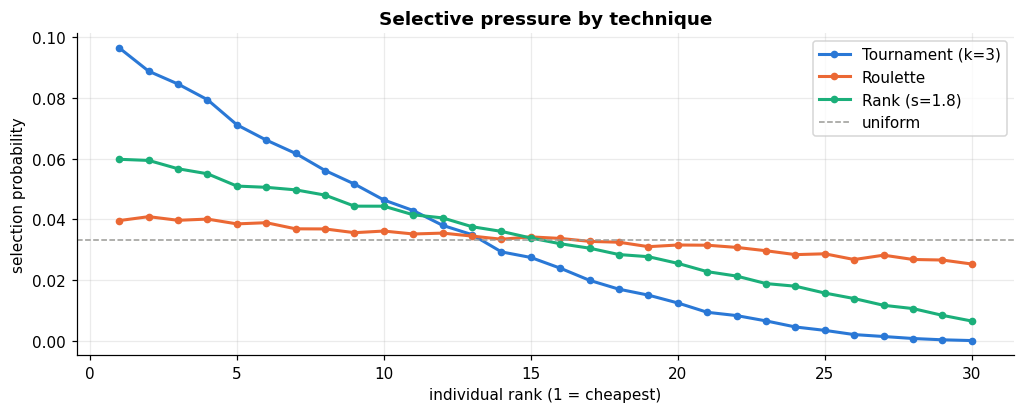

Cost range: 33,559 – 55,250 (the worst costs only 65% more)


In [27]:
def selection_tournament(costs: np.ndarray, n: int, rng: np.random.Generator,
                         k: int = 3) -> np.ndarray:
    """Pick k individuals at random; the cheapest one wins. Repeat n times."""
    contenders = rng.integers(0, len(costs), size=(n, k))
    return contenders[np.arange(n), costs[contenders].argmin(axis=1)]


def selection_roulette(costs: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    """Fitness-proportional selection with fitness = 1 / cost."""
    fitness = 1.0 / costs
    return rng.choice(len(costs), size=n, p=fitness / fitness.sum())


def selection_rank(costs: np.ndarray, n: int, rng: np.random.Generator,
                   pressure: float = 1.8) -> np.ndarray:
    """Linear ranking: probability depends on the position, not on the cost value.

    The best gets ``pressure / N`` and the worst ``(2 - pressure) / N``.
    """
    N = len(costs)
    ranks = np.empty(N)
    ranks[costs.argsort()[::-1]] = np.arange(N)          # worst -> 0, best -> N-1
    probs = ((2 - pressure) + 2 * (pressure - 1) * ranks / max(N - 1, 1)) / N
    return rng.choice(N, size=n, p=probs / probs.sum())


r_med = problemset[problemset.problem_cluster.str.startswith("medium-30")].iloc[3]
P_med = ShoppingProblem(instances[r_med.catalog_path], r_med.query, r_med.fuel_price)
demo_costs = np.sort(P_med.evaluate(init_random(P_med, 30, rng)))
fig, ax = plt.subplots(figsize=(11, 3.8))
for name, fn in [("Tournament (k=3)", selection_tournament), ("Roulette", selection_roulette),
                 ("Rank (s=1.8)", selection_rank)]:
    counts = np.bincount(fn(demo_costs, 100_000, rng), minlength=30) / 100_000
    ax.plot(range(1, 31), counts, marker="o", markersize=4, label=name)
ax.axhline(1 / 30, color="#9a9a96", ls="--", lw=1, label="uniform")
ax.set_xlabel("individual rank (1 = cheapest)")
ax.set_ylabel("selection probability")
ax.set_title("Selective pressure by technique")
ax.legend()
save_fig(fig, "selection_pressure")
plt.show()
print(f"Cost range: {demo_costs.min():,.0f} – {demo_costs.max():,.0f} "
      f"(the worst costs only {100 * (demo_costs.max() / demo_costs.min() - 1):.0f}% more)")

### 11.3 Crossover
All three operators work **position by position**, so a child inherits at gene `i` a store that was already
valid for product `i`: **children are always valid**.

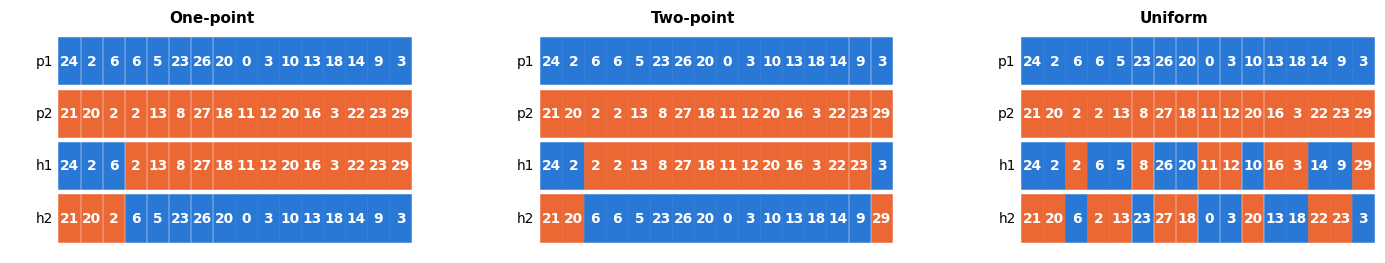

In [28]:
def crossover_one_point(p1: np.ndarray, p2: np.ndarray, rng: np.random.Generator):
    """Cut both parents at the same random point and swap the tails."""
    if len(p1) < 2:
        return p1.copy(), p2.copy()
    cut = rng.integers(1, len(p1))
    return (np.concatenate([p1[:cut], p2[cut:]]),
            np.concatenate([p2[:cut], p1[cut:]]))


def crossover_two_point(p1: np.ndarray, p2: np.ndarray, rng: np.random.Generator):
    """Swap the middle segment between two random cut points."""
    if len(p1) < 3:
        return crossover_one_point(p1, p2, rng)
    a, b = sorted(rng.choice(np.arange(1, len(p1)), size=2, replace=False))
    c1, c2 = p1.copy(), p2.copy()
    c1[a:b], c2[a:b] = p2[a:b], p1[a:b]
    return c1, c2


def crossover_uniform(p1: np.ndarray, p2: np.ndarray, rng: np.random.Generator):
    """Each gene comes from either parent with probability 0.5."""
    mask = rng.random(len(p1)) < 0.5
    return np.where(mask, p1, p2), np.where(mask, p2, p1)


def plot_genes(rows, title, ax, colors):
    for r, (label, genes, row_colors) in enumerate(rows):
        for c, (g, col) in enumerate(zip(genes, row_colors)):
            ax.add_patch(plt.Rectangle((c, -r), 0.94, 0.88, color=col))
            ax.text(c + 0.47, -r + 0.44, str(g), ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        ax.text(-0.3, -r + 0.44, label, ha="right", va="center", fontsize=9)
    ax.set_xlim(-2.2, len(rows[0][1])); ax.set_ylim(-len(rows) + 0.8, 1); ax.axis("off"); ax.set_title(title, fontsize=10)


p1, p2 = init_random(P_med, 2, np.random.default_rng(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 2.6))
for ax, (name, fn) in zip(axes, [("One-point", crossover_one_point), ("Two-point", crossover_two_point),
                                 ("Uniform", crossover_uniform)]):
    c1, c2 = fn(p1, p2, np.random.default_rng(11))
    src_color = lambda child: [PALETTE[0] if a == b else PALETTE[1] for a, b in zip(child, p1)]
    plot_genes([("p1", p1, [PALETTE[0]] * P_med.k), ("p2", p2, [PALETTE[1]] * P_med.k),
                ("h1", c1, src_color(c1)), ("h2", c2, src_color(c2))], name, ax, PALETTE)
save_fig(fig, "crossover")
plt.show()

Blue = gene inherited from `p1`, orange = gene inherited from `p2` (where both parents agree it shows blue).

### 11.4 Mutation
- **Random reset:** the gene jumps to *any* valid store. It explores.
- **Consolidation (heuristic):** the gene moves to a store **the route already visits**. It seeks routes with
  fewer stops, so it exploits.

We added the second one because random reset rarely "discovers" on its own that grouping products in one store saves a
trip. The idea was to give it that push. Spoiler: the benchmark shows it pushes too hard.

We measure their effect on the number of distinct stores in the chromosome:

In [29]:
def mutation_random_reset(chromosome: np.ndarray, problem: ShoppingProblem,
                          rng: np.random.Generator, pm: float) -> np.ndarray:
    """With probability pm, a gene jumps to any store that sells the product."""
    child = chromosome.copy()
    for i in np.flatnonzero(rng.random(len(child)) < pm):
        child[i] = rng.choice(problem.allowed[i])
    return child


def mutation_consolidate(chromosome: np.ndarray, problem: ShoppingProblem,
                         rng: np.random.Generator, pm: float) -> np.ndarray:
    """With probability pm, move a product to a store the route already visits.

    Heuristic mutation: fewer distinct stores means a shorter trip. If no other
    visited store sells the product, it falls back to a random reset.
    """
    child = chromosome.copy()
    for i in np.flatnonzero(rng.random(len(child)) < pm):
        visited = set(np.delete(child, i).tolist())
        options = [s for s in problem.allowed[i] if s in visited and s != child[i]]
        child[i] = rng.choice(options) if options else rng.choice(problem.allowed[i])
    return child


base = init_random(P_med, 2000, np.random.default_rng(5))
summary = {"original": [len(set(c)) for c in base]}
for name, fn in [("random_reset", mutation_random_reset), ("consolidate", mutation_consolidate)]:
    summary[name] = [len(set(fn(c, P_med, rng, pm=0.3))) for c in base]
print(f"Distinct stores per chromosome (k = {P_med.k} products, pm = 0.3)")
pd.DataFrame(summary).describe().loc[["mean", "min", "max"]]

Distinct stores per chromosome (k = 16 products, pm = 0.3)


,original,random_reset,consolidate
mean,12.50,12.52,10.00
min,8.00,8.00,5.00
max,16.00,16.00,14.00


### 11.5 Replacement with elitism and 11.6 termination
- **Elitism:** the `n_elite` best parents survive untouched and the rest of the population is filled with the
  best children. The best cost therefore **never gets worse** between generations.
- **Termination:** stop at the generation limit **or** after `patience` generations without improvement.

In [30]:
def replacement_elitism(population: np.ndarray, costs: np.ndarray,
                        offspring: np.ndarray, offspring_costs: np.ndarray,
                        n_elite: int) -> tuple[np.ndarray, np.ndarray]:
    """Generational replacement that keeps the n_elite best parents untouched."""
    elite = costs.argsort()[:n_elite]
    keep = offspring_costs.argsort()[:len(population) - n_elite]
    return (np.vstack([population[elite], offspring[keep]]),
            np.concatenate([costs[elite], offspring_costs[keep]]))


def should_stop(generation: int, max_generations: int, stall: int, patience: int) -> bool:
    """Stop at the generation limit or after ``patience`` generations without improvement."""
    return generation >= max_generations or stall >= patience


pop_a = init_random(P_med, 6, rng); cost_a = P_med.evaluate(pop_a)
pop_b = init_random(P_med, 6, rng); cost_b = P_med.evaluate(pop_b)
new_pop, new_costs = replacement_elitism(pop_a, cost_a, pop_b, cost_b, n_elite=2)
print("Parents :", np.sort(cost_a).round(0))
print("Children :", np.sort(cost_b).round(0))
print("New    :", new_costs.round(0), "← 2 elites + 4 best children")
print()
for g, stall in [(10, 3), (200, 0), (57, 50)]:
    print(f"should_stop(gen={g}, max=200, stall={stall}, patience=50) = {should_stop(g, 200, stall, 50)}")

Parents : [31957. 36586. 37774. 42184. 45013. 46824.]
Children : [30668. 37556. 38652. 41358. 41852. 42257.]
New    : [31957. 36586. 30668. 37556. 38652. 41358.] ← 2 elites + 4 best children

should_stop(gen=10, max=200, stall=3, patience=50) = False
should_stop(gen=200, max=200, stall=0, patience=50) = True
should_stop(gen=57, max=200, stall=50, patience=50) = True


## 12. The `GeneticShoppingOptimizer` class
It bundles the previous steps, **one method per step**, and takes every hyperparameter in its constructor.
Selection, crossover and mutation are chosen by name, which makes comparing them trivial.

Why a class instead of one big function? Each step stays isolated and can be swapped or tested on its own, and the
benchmarks below boil down to creating the optimizer with different parameters.

In [31]:
@dataclass
class GAResult:
    best_chromosome: np.ndarray
    best_cost: float
    answer: str
    generations: int
    evaluations: int
    elapsed: float
    history: pd.DataFrame = field(repr=False)


class GeneticShoppingOptimizer:
    """Genetic algorithm that minimizes product cost + fuel cost of a shopping trip.

    Hyperparameters
    ---------------
    pop_size      individuals per generation
    generations   maximum number of generations
    pc            crossover probability
    pm            per-gene mutation probability (default 1 / k)
    selection     'tournament' | 'roulette' | 'rank'
    crossover     'one_point' | 'two_point' | 'uniform'
    mutation      'random_reset' | 'consolidate'
    tournament_k  tournament size
    rank_pressure selective pressure for rank selection (1..2)
    elitism       how many of the best parents survive untouched
    patience      stop after this many generations without improvement
    seeding       put the two greedy solutions in the initial population
    seed          random seed (reproducibility)
    """

    CROSSOVERS = {"one_point": crossover_one_point, "two_point": crossover_two_point,
                  "uniform": crossover_uniform}
    MUTATIONS = {"random_reset": mutation_random_reset, "consolidate": mutation_consolidate}

    def __init__(self, problem: ShoppingProblem, pop_size: int = 80, generations: int = 200,
                 pc: float = 0.9, pm: float | None = None, selection: str = "tournament",
                 crossover: str = "uniform", mutation: str = "random_reset",
                 tournament_k: int = 3, rank_pressure: float = 1.8, elitism: int = 2,
                 patience: int = 50, seeding: bool = True, seed: int | None = None):
        self.problem = problem
        self.pop_size = pop_size
        self.generations = generations
        self.pc = pc
        self.pm = pm if pm is not None else 1.0 / problem.k
        self.selection_name, self.crossover_name, self.mutation_name = selection, crossover, mutation
        self.selections = {"tournament": partial(selection_tournament, k=tournament_k),
                           "roulette": selection_roulette,
                           "rank": partial(selection_rank, pressure=rank_pressure)}
        self.elitism = elitism
        self.patience = patience
        self.seeding = seeding
        self.rng = np.random.default_rng(seed)

    # -- one method per step -------------------------------------------------

    def initialize(self) -> np.ndarray:
        if self.seeding:
            seeds = [greedy_cheapest(self.problem), greedy_nearest(self.problem)]
            return init_seeded(self.problem, self.pop_size, self.rng, seeds)
        return init_random(self.problem, self.pop_size, self.rng)

    def evaluate(self, population: np.ndarray) -> np.ndarray:
        return self.problem.evaluate(population)

    def select(self, costs: np.ndarray, n: int) -> np.ndarray:
        return self.selections[self.selection_name](costs, n, self.rng)

    def crossover(self, p1: np.ndarray, p2: np.ndarray):
        if self.rng.random() < self.pc:
            return self.CROSSOVERS[self.crossover_name](p1, p2, self.rng)
        return p1.copy(), p2.copy()

    def mutate(self, chromosome: np.ndarray) -> np.ndarray:
        return self.MUTATIONS[self.mutation_name](chromosome, self.problem, self.rng, self.pm)

    def replace(self, population, costs, offspring, offspring_costs):
        return replacement_elitism(population, costs, offspring, offspring_costs, self.elitism)

    def should_stop(self, generation: int, stall: int) -> bool:
        return should_stop(generation, self.generations, stall, self.patience)

    # -- main loop -----------------------------------------------------------

    def run(self, verbose: bool = False) -> GAResult:
        start = time.perf_counter()
        self.problem.evaluations = 0
        population = self.initialize()
        costs = self.evaluate(population)
        best_idx = costs.argmin()
        best, best_cost = population[best_idx].copy(), costs[best_idx]
        history, generation, stall = [], 0, 0

        while True:
            history.append({"generation": generation, "best": best_cost,
                            "mean": costs.mean(), "worst": costs.max(),
                            "diversity": len(np.unique(population, axis=0)) / len(population)})
            if verbose and generation % 10 == 0:
                print(f"gen {generation:4d} | best {best_cost:12.2f} | mean {costs.mean():12.2f}")
            if self.should_stop(generation, stall):
                break

            parents = self.select(costs, self.pop_size + self.pop_size % 2)
            offspring = []
            for a, b in zip(parents[::2], parents[1::2]):
                for child in self.crossover(population[a], population[b]):
                    offspring.append(self.mutate(child))
            offspring = np.array(offspring)
            population, costs = self.replace(population, costs, offspring, self.evaluate(offspring))

            generation += 1
            if costs.min() < best_cost - 1e-9:
                best_idx = costs.argmin()
                best, best_cost, stall = population[best_idx].copy(), costs[best_idx], 0
            else:
                stall += 1

        return GAResult(best, float(best_cost), self.problem.format_answer(best), generation,
                        self.problem.evaluations, time.perf_counter() - start,
                        pd.DataFrame(history))


# Hyperparameters and their default values
pd.Series({name: p.default for name, p in inspect.signature(GeneticShoppingOptimizer.__init__).parameters.items()
           if p.default is not inspect.Parameter.empty}, name="default").to_frame()

,default
pop_size,80
generations,200
pc,0.90
pm,None
selection,tournament
crossover,uniform
mutation,random_reset
tournament_k,3
rank_pressure,1.80
elitism,2


## 13. Running one problem
A medium problem (30 stores) **without seeding**, to watch the GA evolve from a random population.

In [32]:
r_run = problemset[problemset.problem_cluster.str.startswith("medium-30")].iloc[7]
P_run = ShoppingProblem(instances[r_run.catalog_path], r_run.query, r_run.fuel_price)
print(f"{r_run.problem_cluster} | k = {P_run.k} products | φ = {P_run.fuel_price}")
ga = GeneticShoppingOptimizer(P_run, pop_size=80, generations=300, seeding=False, seed=SEED)
res = ga.run(verbose=True)
print()
print(res.answer)
print(f"Cost = {res.best_cost:,.2f} | best_known = {r_run.best_known:,.2f} | "
      f"generations = {res.generations} | evaluations = {res.evaluations} | {res.elapsed:.2f} s")

medium-30s-80p-f0_10-q1_20-random | k = 16 products | φ = 5.0
gen    0 | best     26619.84 | mean     41155.66


gen   10 | best      9151.84 | mean     14113.49


gen   20 | best      6462.84 | mean      9705.68


gen   30 | best      6136.84 | mean      8603.79
gen   40 | best      5392.84 | mean      8036.29


gen   50 | best      5098.84 | mean      7680.11
gen   60 | best      5083.84 | mean      7760.64


gen   70 | best      5083.84 | mean      7789.15
gen   80 | best      5079.84 | mean      8267.50


gen   90 | best      5079.84 | mean      7275.61
gen  100 | best      5004.84 | mean      7746.74


gen  110 | best      5004.84 | mean      7633.25
gen  120 | best      5004.84 | mean      7710.83


gen  130 | best      5004.84 | mean      7613.56
gen  140 | best      5004.84 | mean      7578.85



RESPUESTA> (Supermercado Precio Justo, Libros de cocina) -> (Supermercado Carrefour, Toallas sanitarias) -> (Supermercado La Fuente, Cremas para pañales) -> (Supermercado El Ahorrón, [Copas menstruales, Pilas AA]) -> (Supermercado Hiper Uno, Paraguas) -> (Olé, [Mostaza, Jugo de naranja]) -> (Supermercado Central, Salsa de pescado) -> (La Sirena, [Aceite de oliva, Ropa de bebé]) -> (Supermercado El Encanto, Filete de res) -> (Supermercado Mr. Food, Pepinos) -> (Supermercado Plaza Lama, Pasta espagueti) -> (Supermercado Los Hidalgos, Pistachos) -> (Supermercado Ever, Vinagre blanco)
Cost = 5,004.84 | best_known = 4,985.84 | generations = 149 | evaluations = 12000 | 2.93 s


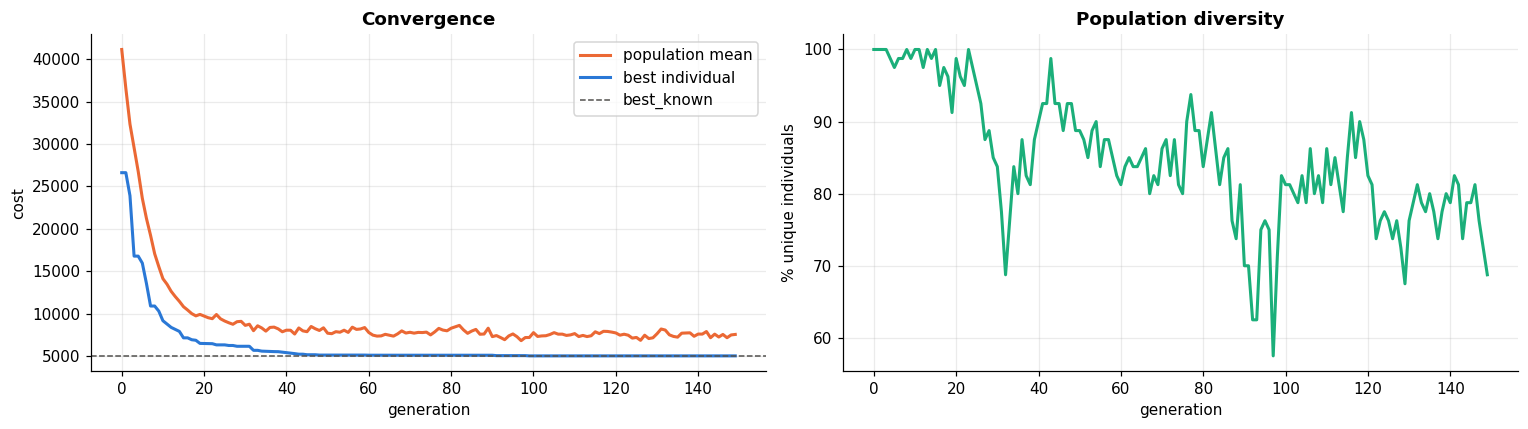

In [33]:
h = res.history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h.generation, h["mean"], label="population mean", color=PALETTE[1])
axes[0].plot(h.generation, h["best"], label="best individual", color=PALETTE[0])
axes[0].axhline(r_run.best_known, ls="--", color="#52514e", lw=1, label="best_known")
axes[0].set_xlabel("generation"); axes[0].set_ylabel("cost")
axes[0].set_title("Convergence"); axes[0].legend()
axes[1].plot(h.generation, 100 * h["diversity"], color=PALETTE[2])
axes[1].set_xlabel("generation"); axes[1].set_ylabel("% unique individuals")
axes[1].set_title("Population diversity")
plt.tight_layout()
save_fig(fig, "convergence")
plt.show()

### 13.1 The route on the real graph
In the `parque` catalog (sparse graph) the best path between stores may go through intermediate nodes.
We rebuild the real path to draw it. We picked this catalog precisely for that: it is the only one where you can see that
the "route" between two stores actually goes through other places.

RESPUESTA> (Supermercado Nacional, Sombra de ojos) -> (Super Pola, [Aceitunas negras, Cables USB, Aretes]) -> (La Sirena, Edredones) -> (Jumbo, Chupetes) -> (Bravo, [Vino tinto, Chicles de menta, Suavizante de telas, Protectores diarios])
Cost = 14,196.90 (best_known = 14,196.90, φ = 9)


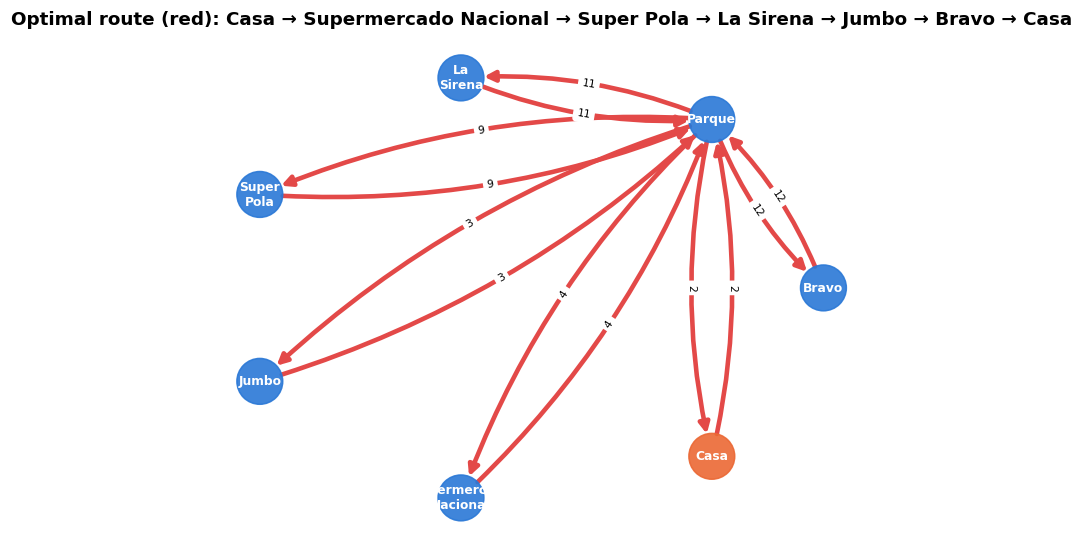

In [34]:
r_pq = problemset[problemset.problem_cluster.str.endswith("parque")].sort_values("k").iloc[-1]
P_pq = ShoppingProblem(instances[r_pq.catalog_path], r_pq.query, r_pq.fuel_price)
res_pq = GeneticShoppingOptimizer(P_pq, seed=SEED).run()
print(res_pq.answer)
print(f"Cost = {res_pq.best_cost:,.2f} (best_known = {r_pq.best_known:,.2f}, φ = {r_pq.fuel_price})")

Gp = nx.DiGraph()
for a, b, d in parque_graph.itertuples(index=False):
    if a != b:
        Gp.add_edge(a, b, weight=d)
stops = ["Casa"] + [s for s, _ in P_pq.decode(res_pq.best_chromosome)] + ["Casa"]
path_edges = set()
for a, b in zip(stops, stops[1:]):
    p = nx.shortest_path(Gp, a, b, weight="weight")
    path_edges |= set(zip(p, p[1:]))
fig, ax = plt.subplots(figsize=(8, 6))
draw_graph(parque_graph, ax, "Optimal route (red): " + " → ".join(stops), highlight=path_edges)
save_fig(fig, "route_parque")
plt.show()

## 14. Baselines and exact optimum
To know how good a solution is we need the **true optimum**. On small problems it can be computed by enumerating
**subsets of stores** ($2^S$ instead of $S^k$ assignments): for each subset buy every product where it is cheapest
*within* the subset and solve the route with Held-Karp.

Since distances already are shortest paths, visiting fewer stores never makes the route longer, so the minimum
over all subsets **is the global optimum**.

In [35]:
def exact_search(problem: ShoppingProblem, max_stores: int = 14) -> tuple[np.ndarray, float]:
    """True optimum by enumerating every subset of candidate stores.

    For a fixed subset the best purchase is the cheapest store of the subset for
    each product, and the route is solved exactly. Since distances already are
    shortest paths, visiting fewer stores is never longer, so the minimum over
    all subsets is the global optimum. Cost grows as 2^S: small instances only.
    """
    candidates = sorted({int(s) for a in problem.allowed for s in a})
    if len(candidates) > max_stores:
        raise ValueError(f"{len(candidates)} candidate stores: too many for exhaustive search")
    best, best_cost = None, np.inf
    for size in range(1, len(candidates) + 1):
        for subset in combinations(candidates, size):
            sub_prices = problem.price[list(subset)]
            if not np.isfinite(sub_prices.min(axis=0)).all():
                continue
            chromosome = np.array(subset)[sub_prices.argmin(axis=0)]
            cost = problem.product_cost(chromosome) + problem.transport_cost(chromosome)
            if cost < best_cost:
                best, best_cost = chromosome, cost
    return best, float(best_cost)


small_rows = problemset[problemset.problem_cluster.str.startswith("small")]
exact_rows = []
for i, r in small_rows.iterrows():
    Pp = ShoppingProblem(instances[r.catalog_path], r.query, r.fuel_price)
    t = time.perf_counter(); _, opt_cost = exact_search(Pp); t_exact = time.perf_counter() - t
    exact_rows.append({"id": i, "cluster": "-".join(r.problem_cluster.split("-")[i] for i in (1, -1)), "exact": opt_cost,
                       "qbf": r["qbf best value"], "best_known": r.best_known, "t_exact": t_exact})
exact_df = pd.DataFrame(exact_rows).set_index("id")
print(f"Small problems: {len(exact_df)} | mean exact time: {1000 * exact_df.t_exact.mean():.1f} ms")
print(f"exact ≤ best_known everywhere? {(exact_df.exact <= exact_df.best_known + 1e-6).all()}")
print(f"Problems where exact BEATS the reference: {(exact_df.exact < exact_df.best_known - 1e-6).sum()}")
exact_df.assign(gain=exact_df.best_known - exact_df.exact).groupby("cluster").agg(
    n=("gain", "size"), improved=("gain", lambda g: (g > 1e-6).sum()),
    mean_saving=("gain", "mean"), max_saving=("gain", "max"))

Small problems: 100 | mean exact time: 1.0 ms
exact ≤ best_known everywhere? True
Problems where exact BEATS the reference: 12


,n,improved,mean_saving,max_saving
cluster,,,,
3s-random,4,0,0.00,0.00
5s-jumbocheap,16,4,30.00,180.00
5s-parque,16,0,0.00,0.00
5s-punico,16,1,7.88,126.00
5s-random,16,3,11.25,90.00
5s-same_dist,16,4,15.00,90.00
5s-same_price,16,0,0.00,0.00


The "quasi brute force" reference **is not always optimal**: our exact method finds cheaper solutions on
several problems. This matters when reading the metrics, because a **negative error** means we beat the reference.

## 15. Validation on the 136 problems
We run the GA over the whole dataset **in parallel** (`joblib`, one process per CPU core) in two variants:
- **GA (seeding):** default configuration, initial population seeded with the greedy solutions.
- **GA (random):** no seeding, the "pure" GA.

We also recompute our greedy baselines (with optimal routing) and compare against the dataset's 4 references.

We run two GA variants to be honest about the result: if we only showed the seeded version, nobody could tell how much of
the merit belongs to the GA and how much to the heuristics it starts from. We parallelize because every problem is
independent, which is the ideal case for spreading work across cores.

In [36]:
def error_columns(pred: np.ndarray, true: np.ndarray) -> pd.DataFrame:
    """Per-problem errors: E (signed), AE (absolute), RE (relative)."""
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    E = pred - true
    return pd.DataFrame({"E": E, "AE": np.abs(E), "RE": E / true})


def summary_metrics(pred: np.ndarray, true: np.ndarray, tol: float = 1e-6) -> dict:
    """Aggregate metrics: ME, MAE, MSE, RMSE, MAPE, max AE, R2 and hit rate.

    hit rate = share of problems where the solver matches or beats the reference.
    """
    pred, true = np.asarray(pred, float), np.asarray(true, float)
    ok = ~(np.isnan(pred) | np.isnan(true))
    pred, true = pred[ok], true[ok]
    E = pred - true
    ss_res, ss_tot = (E ** 2).sum(), ((true - true.mean()) ** 2).sum()
    return {
        "n": int(ok.sum()),
        "ME": E.mean(),
        "MAE": np.abs(E).mean(),
        "MSE": (E ** 2).mean(),
        "RMSE": np.sqrt((E ** 2).mean()),
        "MAPE_%": 100 * np.abs(E / true).mean(),
        "max_AE": np.abs(E).max(),
        "R2": 1 - ss_res / ss_tot if ss_tot > 0 else np.nan,
        "hit_rate_%": 100 * (E <= tol).mean(),
    }


def run_ga(instance, query, fuel, seed, **config):
    problem = ShoppingProblem(instance, query, fuel)
    result = GeneticShoppingOptimizer(problem, seed=seed, **config).run()
    return {"cost": result.best_cost, "generations": result.generations, "evaluations": result.evaluations,
            "time": result.elapsed, "answer": result.answer,
            "cache_hit_%": 100 * problem.router.hits / max(problem.router.hits + problem.router.misses, 1)}


def run_all(rows, configs, seeds=(SEED,)):
    jobs = [(i, name, s) for i in rows.index for name in configs for s in seeds]
    out = Parallel(n_jobs=N_JOBS)(
        delayed(run_ga)(instances[rows.loc[i, "catalog_path"]], rows.loc[i, "query"], rows.loc[i, "fuel_price"], s, **configs[name])
        for i, name, s in jobs)
    return pd.DataFrame([{"id": i, "config": name, "seed": s, **o} for (i, name, s), o in zip(jobs, out)])


val = cached("runs_validation", lambda: run_all(problemset, {"seeded": {"seeding": True}, "random": {"seeding": False}}))

results = problemset[["problem_cluster", "k", "fuel_price", "log10_space", "best_known", "qbf best value",
                      "ga best value", "gc best value", "gn best value"]].copy()
results["GA_seeded"] = val[val.config == "seeded"].set_index("id")["cost"]
results["GA_random"] = val[val.config == "random"].set_index("id")["cost"]
results["time_seeded"] = val[val.config == "seeded"].set_index("id")["time"]
results["generations"] = val[val.config == "seeded"].set_index("id")["generations"]
results["cache_hit_%"] = val[val.config == "seeded"].set_index("id")["cache_hit_%"]
results["exact"] = exact_df["exact"]
for i, r in problemset.iterrows():
    Pp = ShoppingProblem(instances[r.catalog_path], r.query, r.fuel_price)
    results.loc[i, "greedy_cheapest"] = Pp.cost(greedy_cheapest(Pp))
    results.loc[i, "greedy_nearest"] = Pp.cost(greedy_nearest(Pp))
results["size"] = results.problem_cluster.str.split("-").str[0]
results.to_csv(RESULTS_DIR / "validation_results.csv")
results[["problem_cluster", "k", "best_known", "exact", "GA_seeded", "GA_random", "greedy_cheapest", "greedy_nearest"]].head(10)

📂 Loaded from results/runs_validation.csv  (RECOMPUTE = True to recompute)


,problem_cluster,k,best_known,exact,GA_seeded,GA_random,greedy_cheapest,greedy_nearest
0,small-3s-4p-f1_10-q1_4-random,1,"4,401.99","4,401.99","4,401.99","4,401.99","4,401.99","4,401.99"
1,small-3s-4p-f1_10-q1_4-random,4,"11,270.96","11,270.96","11,270.96","11,270.96","11,270.96","12,817.96"
2,small-3s-4p-f1_10-q1_4-random,1,"4,501.99","4,501.99","4,501.99","4,501.99","4,501.99","4,501.99"
3,small-3s-4p-f1_10-q1_4-random,4,"11,400.96","11,400.96","11,400.96","11,400.96","11,400.96","12,917.96"
4,small-5s-10p-f0_10-q1_10-random,1,619.99,619.99,619.99,619.99,619.99,"3,638.99"
5,small-5s-10p-f0_10-q1_10-random,4,"5,455.96","5,455.96","5,455.96","5,455.96","5,455.96","15,594.96"
6,small-5s-10p-f0_10-q1_10-random,7,"7,183.93","7,183.93","7,183.93","7,183.93","7,183.93","19,061.93"
7,small-5s-10p-f0_10-q1_10-random,10,"11,082.90","11,082.90","11,082.90","11,082.90","11,082.90","28,819.90"
8,small-5s-10p-f0_10-q1_10-random,1,"1,123.99","1,123.99","1,123.99","1,123.99","1,123.99","3,567.99"
9,small-5s-10p-f0_10-q1_10-random,4,"5,643.96","5,643.96","5,643.96","5,643.96","5,643.96","12,526.96"


### 15.1 Global metrics (against the references' `best_known`)
- **E** = predicted − reference (signed; negative = better than the reference)
- **AE** = |E| · **RE** = E / reference · **MAE**, **MSE**, **RMSE**, **MAPE**, **R²**
- **hit rate** = % of problems where we match or beat the reference

⚠️ When we **beat** the reference the absolute error grows too. So an MAE > 0 is not always bad: read it together
with **ME** (signed) and the **hit rate**.

In [37]:
solvers = {"GA (seeding) — ours": "GA_seeded", "GA (random) — ours": "GA_random",
           "Greedy cheapest — ours": "greedy_cheapest", "Greedy nearest — ours": "greedy_nearest",
           "ref: GA": "ga best value", "ref: quasi brute force": "qbf best value",
           "ref: greedy cheapest": "gc best value", "ref: greedy nearest": "gn best value"}
global_metrics = pd.DataFrame({name: summary_metrics(results[col], results.best_known) for name, col in solvers.items()}).T
global_metrics.to_csv(RESULTS_DIR / "global_metrics.csv")
global_metrics.style.format("{:,.3f}").format({"n": "{:.0f}"}).background_gradient(subset=["MAE"], cmap="Blues")

,n,ME,MAE,MSE,RMSE,MAPE_%,max_AE,R2,hit_rate_%
GA (seeding) — ours,136,-16.808824,16.808824,1793.191176,42.346088,0.345250,180.000000,0.999924,100.000000
GA (random) — ours,136,-13.161765,18.897059,1987.617647,44.582706,0.501835,180.000000,0.999916,94.852941
Greedy cheapest — ours,136,-13.867647,17.397059,1647.367647,40.587777,0.730849,180.000000,0.999931,91.911765
Greedy nearest — ours,136,9368.294118,9368.294118,192825109.897059,13886.148130,353.115708,39523.000000,-7.124776,13.970588
ref: GA,133,1773.195489,1773.195489,17897149.300752,4230.502252,48.671601,20006.000000,0.044051,40.601504
ref: quasi brute force,99,301.535354,301.535354,585282.808081,765.037782,3.383928,2727.000000,0.977421,78.787879
ref: greedy cheapest,136,11.323529,11.323529,1029.294118,32.082614,0.596722,180.000000,0.999957,77.941176
ref: greedy nearest,136,9607.397059,9607.397059,226367851.617647,15045.525967,352.859890,50809.000000,-8.538115,12.500000


In [38]:
by_cluster = results.groupby("problem_cluster").apply(lambda g: pd.Series({
    "n": len(g),
    "MAE GA seeding": summary_metrics(g.GA_seeded, g.best_known)["MAE"],
    "MAE GA random": summary_metrics(g.GA_random, g.best_known)["MAE"],
    "MAE ref GA": summary_metrics(g["ga best value"], g.best_known)["MAE"],
    "ME GA seeding": summary_metrics(g.GA_seeded, g.best_known)["ME"],
    "hit_% GA seeding": summary_metrics(g.GA_seeded, g.best_known)["hit_rate_%"],
    "% exact optimum": 100 * (abs(g.GA_seeded - g.exact) < 1e-6).mean() if g.exact.notna().all() else np.nan,
    "mean time (s)": g.time_seeded.mean(),
}))
by_cluster

,n,MAE GA seeding,MAE GA random,MAE ref GA,ME GA seeding,hit_% GA seeding,% exact optimum,mean time (s)
problem_cluster,,,,,,,,
big-100s-300p-f0_10-q1_20-random,12.00,0.00,22.67,"5,177.42",0.00,100.00,NaN,2.12
medium-20s-50p-f0_10-q1_20-random,12.00,49.25,49.25,"4,361.08",-49.25,100.00,NaN,2.87
medium-30s-80p-f0_10-q1_20-random,12.00,55.75,48.50,"5,974.75",-55.75,100.00,NaN,3.44
small-3s-4p-f1_10-q1_4-random,4.00,0.00,0.00,22.75,0.00,100.00,100.00,0.12
small-5s-10p-f0_10-q1_10-jumbocheap,16.00,30.00,30.00,"1,163.44",-30.00,100.00,100.00,0.08
small-5s-10p-f0_10-q1_10-parque,16.00,0.00,0.00,299.50,-0.00,100.00,100.00,0.08
small-5s-10p-f0_10-q1_10-punico,16.00,7.88,7.88,518.69,-7.87,100.00,100.00,0.07
small-5s-10p-f0_10-q1_10-random,16.00,11.25,11.25,647.63,-11.25,100.00,100.00,0.10
small-5s-10p-f0_10-q1_10-same_dist,16.00,15.00,15.00,547.56,-15.00,100.00,100.00,0.08


Small problems where the GA finds the EXACT OPTIMUM: 100/100 (100.0%)
Problems where the GA BEATS the best known reference: 30/136
Total savings vs best_known: 2,286.00


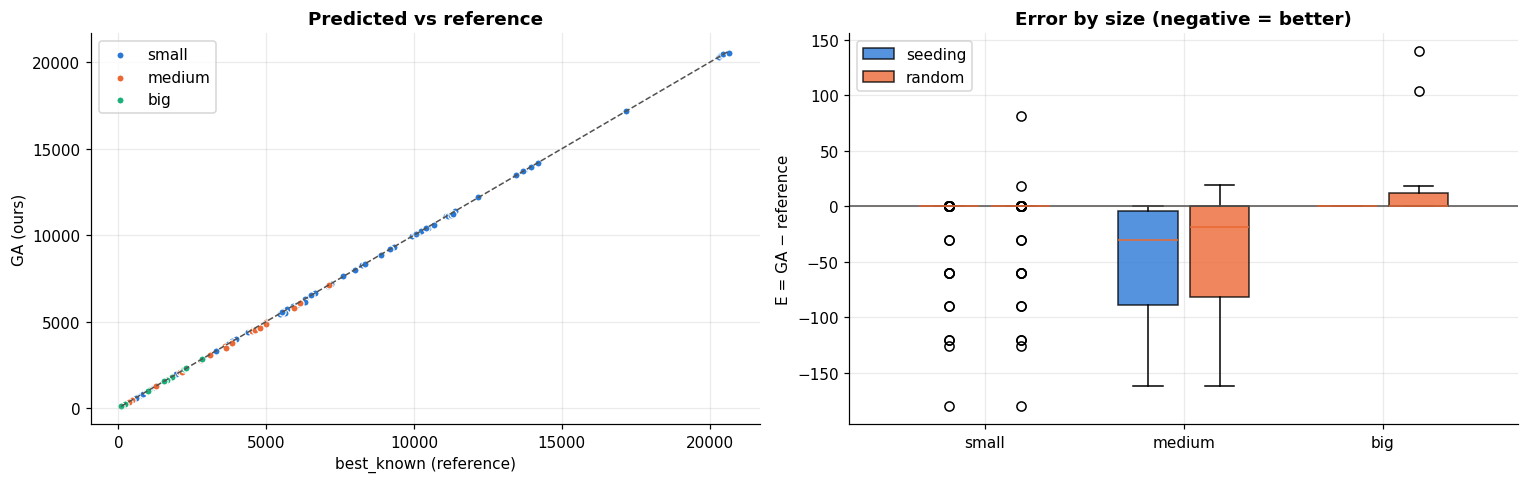

In [39]:
small_mask = results.exact.notna()
optimal = (abs(results.loc[small_mask, "GA_seeded"] - results.loc[small_mask, "exact"]) < 1e-6)
improved = (results.GA_seeded < results.best_known - 1e-6)
print(f"Small problems where the GA finds the EXACT OPTIMUM: {optimal.sum()}/{len(optimal)} ({100 * optimal.mean():.1f}%)")
print(f"Problems where the GA BEATS the best known reference: {improved.sum()}/{len(results)}")
print(f"Total savings vs best_known: {(results.best_known - results.GA_seeded).sum():,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
err = results.GA_seeded - results.best_known
for j, size in enumerate(["small", "medium", "big"]):
    m = results["size"] == size
    axes[0].scatter(results.loc[m, "best_known"], results.loc[m, "GA_seeded"], s=22, color=PALETTE[j], label=size,
                    edgecolor="white", linewidth=0.8)
lim = [results.best_known.min(), results.best_known.max()]
axes[0].plot(lim, lim, color="#52514e", lw=1, ls="--")
axes[0].set_xlabel("best_known (reference)"); axes[0].set_ylabel("GA (ours)")
axes[0].set_title("Predicted vs reference"); axes[0].legend()
data_box = [results.loc[results["size"] == s, "GA_seeded"] - results.loc[results["size"] == s, "best_known"] for s in ["small", "medium", "big"]]
data_box_r = [results.loc[results["size"] == s, "GA_random"] - results.loc[results["size"] == s, "best_known"] for s in ["small", "medium", "big"]]
pos = np.arange(3)
b1 = axes[1].boxplot(data_box, positions=pos - 0.18, widths=0.3, patch_artist=True, showfliers=True)
b2 = axes[1].boxplot(data_box_r, positions=pos + 0.18, widths=0.3, patch_artist=True, showfliers=True)
for b, c in [(b1, PALETTE[0]), (b2, PALETTE[1])]:
    for patch in b["boxes"]:
        patch.set_facecolor(c); patch.set_alpha(0.8)
axes[1].set_xticks(pos, ["small", "medium", "big"]); axes[1].axhline(0, color="#52514e", lw=1)
axes[1].set_ylabel("E = GA − reference"); axes[1].set_title("Error by size (negative = better)")
axes[1].legend([b1["boxes"][0], b2["boxes"][0]], ["seeding", "random"])
plt.tight_layout()
save_fig(fig, "validation")
plt.show()

## 16. Technique benchmark: 3 selections × 3 crossovers × 2 mutations
We compare all 18 combinations **without seeding** (to measure the operator, not the initial heuristic) on the
24 medium and big problems with 30 and 100 stores, which is where differences show, with 2 seeds each.
Quality metric: **RE %** = relative error against `best_known`.

In [40]:
bench_rows = problemset[problemset.problem_cluster.str.startswith(("medium-30", "big"))]
configs = {f"{s}|{c}|{m}": {"selection": s, "crossover": c, "mutation": m, "seeding": False}
           for s in ["tournament", "roulette", "rank"] for c in ["one_point", "two_point", "uniform"]
           for m in ["random_reset", "consolidate"]}
bench = cached("runs_operator_benchmark", lambda: run_all(bench_rows, configs, seeds=(1, 2)))
bench[["selection", "crossover", "mutation"]] = bench.config.str.split("|", expand=True)
bench["RE_%"] = 100 * (bench.cost - problemset.loc[bench.id, "best_known"].to_numpy()) / problemset.loc[bench.id, "best_known"].to_numpy()
bench.to_csv(RESULTS_DIR / "operator_benchmark.csv", index=False)
ranking = bench.groupby(["selection", "crossover", "mutation"]).agg(
    RE_mean=("RE_%", "mean"), RE_std=("RE_%", "std"), time_s=("time", "mean"),
    generations=("generations", "mean"), evaluations=("evaluations", "mean")).sort_values("RE_mean")
ranking.style.format("{:.3f}").format({"generations": "{:.0f}", "evaluations": "{:,.0f}"}).background_gradient(subset=["RE_mean"], cmap="Blues")

📂 Loaded from results/runs_operator_benchmark.csv  (RECOMPUTE = True to recompute)


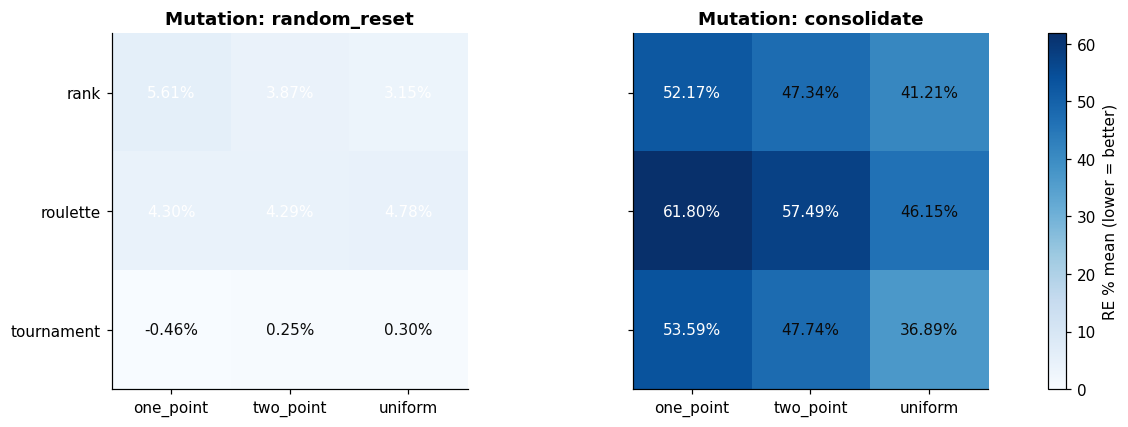

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, mut in zip(axes, ["random_reset", "consolidate"]):
    pivot = bench[bench.mutation == mut].pivot_table(index="selection", columns="crossover", values="RE_%", aggfunc="mean")
    im = ax.imshow(pivot.to_numpy(), cmap="Blues", vmin=0, vmax=bench.groupby(["selection", "crossover", "mutation"])["RE_%"].mean().max())
    ax.set_xticks(range(3), pivot.columns); ax.set_yticks(range(3), pivot.index); ax.grid(False)
    for i in range(3):
        for j in range(3):
            v = pivot.to_numpy()[i, j]
            ax.text(j, i, f"{v:.2f}%", ha="center", va="center", color="white" if v > pivot.to_numpy().mean() else "#0b0b0b")
    ax.set_title(f"Mutation: {mut}")
fig.colorbar(im, ax=axes, label="RE % mean (lower = better)")
save_fig(fig, "operator_heatmap")
plt.show()

**Benchmark findings:**
- **Mutation decides almost everything.** With *random reset* the mean RE is ≈ 3 %, and with *consolidation* it rises
  to ≈ 49 %. Consolidation packs products into few stores too fast, diversity collapses and the GA converges
  **prematurely** (it stops earlier: ~75 generations vs ~120).
- **Tournament** is the best selection: ≈ 0 % RE with random reset, and also the fastest. Roulette and rank stay at
  3–6 %, consistent with the low selective pressure seen in section 11.2.
- The **crossover** type matters little compared to the other two factors.

### 16.1 Memory and time per technique
We measure **peak memory** with `tracemalloc` by running each combination on a medium problem (20 stores)
sequentially, so processes don't interfere. `tracemalloc` slows everything down, so times here are only
meaningful relative to each other.

In [42]:
r_mem = problemset[problemset.problem_cluster.str.startswith("medium-20")].sort_values("k").iloc[-1]


def memory_benchmark():
    rows = []
    for name, cfg in configs.items():
        P_b = ShoppingProblem(instances[r_mem.catalog_path], r_mem.query, r_mem.fuel_price)
        tracemalloc.start()
        res_b = GeneticShoppingOptimizer(P_b, seed=1, **cfg).run()
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        rows.append({"config": name, "peak_MB": peak / 2**20, "time_s": res_b.elapsed, "generations": res_b.generations,
                     "RE_%": 100 * (res_b.best_cost - r_mem.best_known) / r_mem.best_known})
    return pd.DataFrame(rows)


mem = cached("memory_benchmark", memory_benchmark, parallel=False).set_index("config").sort_values("RE_%")
mem

📂 Loaded from results/memory_benchmark.csv  (RECOMPUTE = True to recompute)


,peak_MB,time_s,generations,RE_%
config,,,,
tournament|one_point|random_reset,2.62,12.89,126,-2.71
tournament|two_point|random_reset,2.57,11.88,102,-2.71
roulette|one_point|random_reset,7.19,29.66,156,-2.71
tournament|uniform|random_reset,2.93,11.12,99,-2.71
rank|uniform|random_reset,7.29,28.11,175,-2.71
rank|one_point|random_reset,6.39,23.56,155,-2.52
rank|two_point|random_reset,7.87,34.74,192,-2.12
roulette|two_point|random_reset,7.47,31.89,186,-1.23
roulette|uniform|random_reset,9.33,46.25,197,-0.76


## 17. Hyperparameter sensitivity and scalability
We vary **one hyperparameter at a time** around the base configuration (tournament + uniform + random reset,
no seeding) on the same 24 problems. Changing one at a time won't find the best possible combination, but it shows the
effect of each parameter on its own, which is what we care about to understand them.

📂 Loaded from results/runs_sensitivity.csv  (RECOMPUTE = True to recompute)


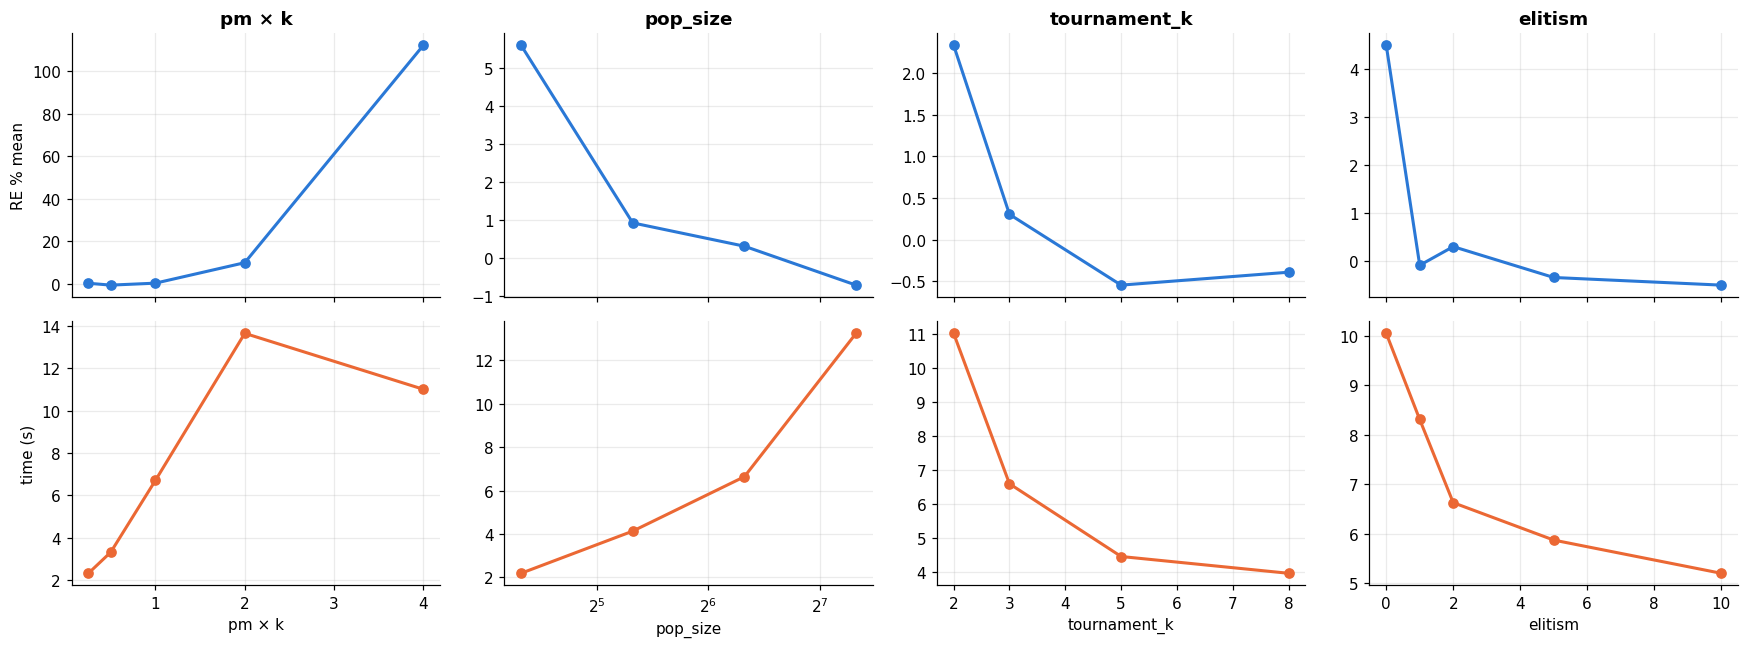

In [43]:
base_cfg = {"selection": "tournament", "crossover": "uniform", "mutation": "random_reset", "seeding": False}
grid = {
    "pm × k": [("pm", v) for v in [0.25, 0.5, 1.0, 2.0, 4.0]],
    "pop_size": [("pop_size", v) for v in [20, 40, 80, 160]],
    "tournament_k": [("tournament_k", v) for v in [2, 3, 5, 8]],
    "elitism": [("elitism", v) for v in [0, 1, 2, 5, 10]],
}
sens_configs = {}
for param, values in grid.items():
    for key, v in values:
        cfg = dict(base_cfg)
        if key == "pm":
            cfg["pm_factor"] = v
        else:
            cfg[key] = v
        sens_configs[f"{param}={v}"] = cfg


def run_sens(instance, query, fuel, seed, pm_factor=None, **cfg):
    if pm_factor is not None:
        cfg["pm"] = pm_factor / len(query)
    return run_ga(instance, query, fuel, seed, **cfg)


def sensitivity_runs():
    jobs = [(i, n, s) for i in bench_rows.index for n in sens_configs for s in (1, 2)]
    out = Parallel(n_jobs=N_JOBS)(delayed(run_sens)(instances[problemset.loc[i, "catalog_path"]], problemset.loc[i, "query"],
                                                    problemset.loc[i, "fuel_price"], s, **sens_configs[n]) for i, n, s in jobs)
    return pd.DataFrame([{"id": i, "config": n, **o} for (i, n, s), o in zip(jobs, out)])


sens = cached("runs_sensitivity", sensitivity_runs)
sens[["param", "value"]] = sens.config.str.split("=", expand=True)
sens["value"] = sens.value.astype(float)
sens["RE_%"] = 100 * (sens.cost - problemset.loc[sens.id, "best_known"].to_numpy()) / problemset.loc[sens.id, "best_known"].to_numpy()
sens.to_csv(RESULTS_DIR / "hyperparameter_sensitivity.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex="col")
for j, param in enumerate(grid):
    g = sens[sens.param == param].groupby("value").agg(RE=("RE_%", "mean"), t=("time", "mean"))
    axes[0, j].plot(g.index, g.RE, marker="o", color=PALETTE[0]); axes[0, j].set_title(param)
    axes[1, j].plot(g.index, g.t, marker="o", color=PALETTE[1]); axes[1, j].set_xlabel(param)
    if param == "pop_size":
        axes[0, j].set_xscale("log", base=2); axes[1, j].set_xscale("log", base=2)
axes[0, 0].set_ylabel("RE % mean"); axes[1, 0].set_ylabel("time (s)")
plt.tight_layout()
save_fig(fig, "sensitivity")
plt.show()

**Reading the sensitivity:**
- **`pm`** is the most delicate parameter. Between 0.25/k and 1/k the GA works well, but at 2/k RE rises to ≈ 10 % and at
  4/k it exceeds 100 %. Too much mutation turns the search into a random walk.
- **Elitism**: with no elites (0) the best individual can be lost and RE rises to ≈ 4.5 %. With 1 to 10 elites RE stays near
  0 and convergence is faster.
- **`pop_size`**: a bigger population gives better quality, but time grows almost linearly. 80 is a good balance.
- **`tournament_k`**: k = 5 beats k = 3 (more selective pressure), but k = 8 brings no further gain.

Since these values were tuned on the same 24 problems, making them the defaults would be *overfitting*. We keep them
documented as a recommendation.

### 17.1 Scalability
How do time and quality grow with problem size? We also compare the theoretical cost of the exact method
($2^S$ subsets) with the GA's (about `pop_size × generations` evaluations, independent of $S$).

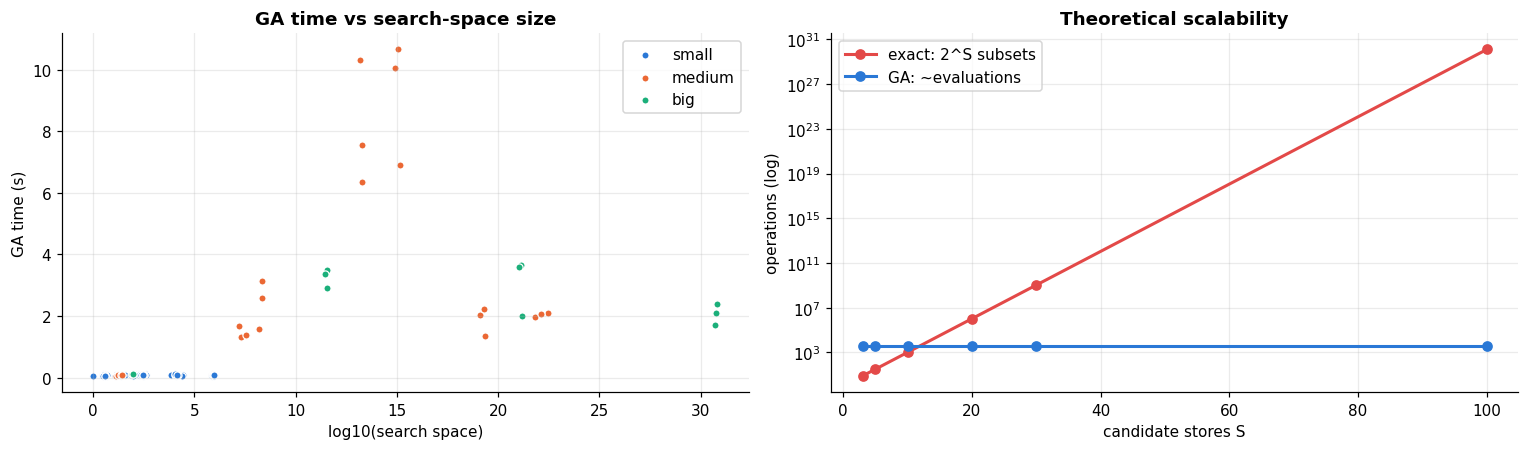

,time_seeded,generations,cache_hit_%
size,,,
big,2.12,50.00,47.69
medium,3.16,54.71,70.29
small,0.08,50.11,99.67


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for j, size in enumerate(["small", "medium", "big"]):
    m = results["size"] == size
    axes[0].scatter(results.loc[m, "log10_space"], results.loc[m, "time_seeded"], s=22, color=PALETTE[j], label=size,
                    edgecolor="white", linewidth=0.8)
axes[0].set_xlabel("log10(search space)"); axes[0].set_ylabel("GA time (s)")
axes[0].set_title("GA time vs search-space size"); axes[0].legend()

S = np.array([3, 5, 10, 20, 30, 100])
axes[1].semilogy(S, 2.0 ** S, marker="o", label="exact: 2^S subsets", color=PALETTE[7])
axes[1].semilogy(S, np.full(len(S), results.generations.mean() * 80), marker="o", label="GA: ~evaluations", color=PALETTE[0])
axes[1].set_xlabel("candidate stores S"); axes[1].set_ylabel("operations (log)")
axes[1].set_title("Theoretical scalability"); axes[1].legend()
plt.tight_layout()
save_fig(fig, "scalability")
plt.show()
results.groupby("size")[["time_seeded", "generations", "cache_hit_%"]].mean()

## 18. Experiment: is the GPU worth it?
To make evaluation vectorizable on the GPU, the route follows the **gene order** (like the reference
solutions) instead of the TSP. We evaluate populations of $10^2$ to $10^6$ individuals with NumPy (CPU),
PyTorch (CPU) and PyTorch (CUDA).

This experiment exists because "why not use the GPU?" is a fair question, and the right answer is a measurement, not an
opinion.

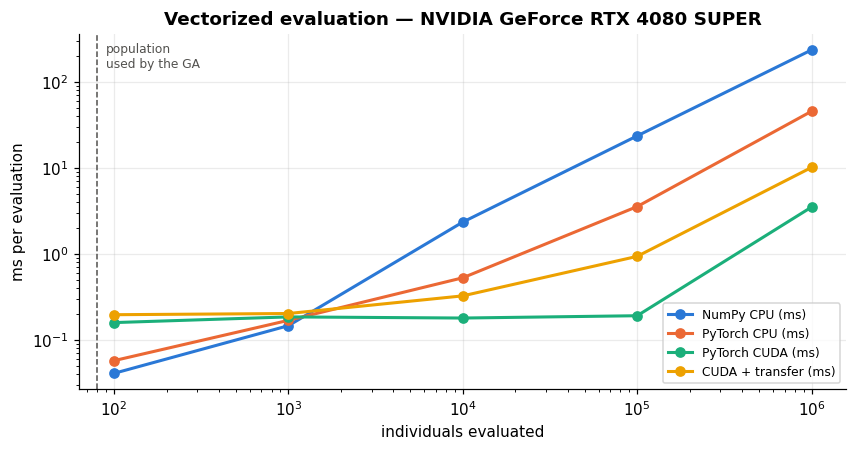

,NumPy CPU (ms),PyTorch CPU (ms),PyTorch CUDA (ms),CUDA + transfer (ms)
population,,,,
100,0.04,0.06,0.16,0.20
1000,0.15,0.17,0.19,0.20
10000,2.35,0.53,0.18,0.33
100000,23.52,3.55,0.19,0.94
1000000,234.26,45.42,3.50,10.12


In [45]:
def batch_cost_numpy(population: np.ndarray, price: np.ndarray, D: np.ndarray,
                     fuel_price: float) -> np.ndarray:
    k = population.shape[1]
    products = price[population, np.arange(k)].sum(axis=1)
    points = np.pad(population + 1, ((0, 0), (1, 1)))            # home ... home
    distance = D[points[:, :-1], points[:, 1:]].sum(axis=1)
    return products + fuel_price * distance


def batch_cost_torch(population, price, D, fuel_price: float):
    import torch
    k = population.shape[1]
    products = price[population, torch.arange(k, device=population.device)].sum(dim=1)
    points = torch.nn.functional.pad(population + 1, (1, 1))
    distance = D[points[:, :-1], points[:, 1:]].sum(dim=1)
    return products + fuel_price * distance


def bench_fn(fn, repeat=5, sync=None):
    fn()
    if sync: sync()
    t = time.perf_counter()
    for _ in range(repeat):
        fn()
    if sync: sync()
    return 1000 * (time.perf_counter() - t) / repeat


r_big = problemset[problemset.problem_cluster.str.startswith("big")].sort_values("k").iloc[-1]
P_g = ShoppingProblem(instances[r_big.catalog_path], r_big.query, r_big.fuel_price)
price_np = np.where(np.isinf(P_g.price), 1e9, P_g.price)
gpu_rows = []
for n in [10**2, 10**3, 10**4, 10**5, 10**6]:
    pop_np = init_random(P_g, 1000, rng)[rng.integers(0, 1000, n)]
    rec = {"population": n, "NumPy CPU (ms)": bench_fn(lambda: batch_cost_numpy(pop_np, price_np, P_g.instance.D, P_g.fuel_price))}
    if torch is not None:
        for dev in ["cpu"] + (["cuda"] if GPU else []):
            pt, pr, dt = (torch.as_tensor(x, device=dev) for x in (pop_np, price_np, P_g.instance.D))
            sync = torch.cuda.synchronize if dev == "cuda" else None
            rec[f"PyTorch {dev.upper()} (ms)"] = bench_fn(lambda: batch_cost_torch(pt, pr, dt, P_g.fuel_price), sync=sync)
            if dev == "cuda":
                rec["CUDA + transfer (ms)"] = bench_fn(
                    lambda: batch_cost_torch(torch.as_tensor(pop_np, device="cuda"), pr, dt, P_g.fuel_price).cpu(), sync=sync)
    gpu_rows.append(rec)
gpu_df = pd.DataFrame(gpu_rows).set_index("population")
gpu_df.to_csv(RESULTS_DIR / "cpu_vs_gpu.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
for j, col in enumerate(gpu_df.columns):
    ax.loglog(gpu_df.index, gpu_df[col], marker="o", label=col, color=PALETTE[j])
ax.axvline(80, color="#52514e", ls="--", lw=1)
ax.text(90, ax.get_ylim()[1] * 0.4, "population\nused by the GA", fontsize=8, color="#52514e")
ax.set_xlabel("individuals evaluated"); ax.set_ylabel("ms per evaluation")
ax.set_title(f"Vectorized evaluation — {GPU or 'CPU only'}"); ax.legend(fontsize=8)
save_fig(fig, "cpu_vs_gpu")
plt.show()
gpu_df

**Experiment takeaway:**
- With **80 individuals** (what the GA uses), NumPy on the CPU is the fastest: launching work on the GPU costs more than
  the computation itself.
- From **~10⁴ individuals** the GPU wins. At **10⁶**, CUDA is ~80× faster than NumPy, or ~20–25× including the data copy.
- Still, the GA's real bottleneck is the **TSP decoder** (dynamic programming, dictionaries), which does not vectorize.
  That is why we parallelize *across problems* on the CPU.
- **When it would pay off:** a "massive" GA evolving hundreds of thousands of individuals, or all problems at once, as
  GPU tensors. Left as future work.

## 19. Data-flow diagram
Everything above summarized in one picture: what goes in, what gets transformed and what comes out. It is the view worth
keeping in mind before reading the package code in `src/`.

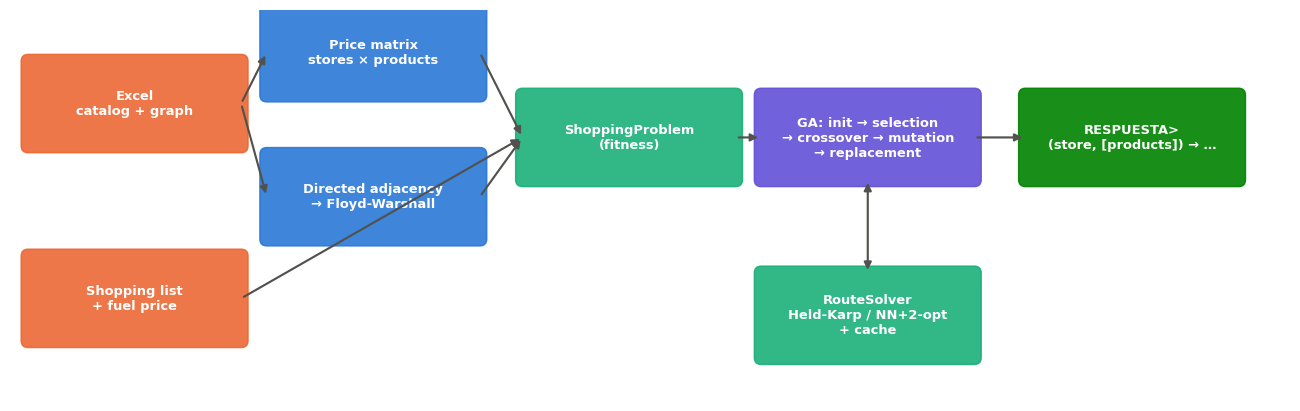

In [46]:
fig, ax = plt.subplots(figsize=(15, 4.6))
ax.axis("off"); ax.set_xlim(0, 15); ax.set_ylim(0, 4.6)
boxes = {
    "xlsx": (0.2, 3.0, "Excel\ncatalog + graph", PALETTE[1]),
    "price": (3.0, 3.6, "Price matrix\nstores × products", PALETTE[0]),
    "dist": (3.0, 1.9, "Directed adjacency\n→ Floyd-Warshall", PALETTE[0]),
    "query": (0.2, 0.7, "Shopping list\n+ fuel price", PALETTE[1]),
    "problem": (6.0, 2.6, "ShoppingProblem\n(fitness)", PALETTE[2]),
    "ga": (8.8, 2.6, "GA: init → selection\n→ crossover → mutation\n→ replacement", PALETTE[6]),
    "tsp": (8.8, 0.5, "RouteSolver\nHeld-Karp / NN+2-opt\n+ cache", PALETTE[2]),
    "out": (11.9, 2.6, "RESPUESTA>\n(store, [products]) → …", PALETTE[5]),
}
for x, y, text, color in boxes.values():
    ax.add_patch(matplotlib.patches.FancyBboxPatch((x, y), 2.5, 1.0, boxstyle="round,pad=0.08", color=color, alpha=0.9))
    ax.text(x + 1.25, y + 0.5, text, ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
arrow = dict(arrowstyle="-|>", color="#52514e", lw=1.4)
for a, b in [("xlsx", "price"), ("xlsx", "dist"), ("price", "problem"), ("dist", "problem"), ("query", "problem"),
             ("problem", "ga"), ("ga", "out")]:
    xa, ya = boxes[a][0] + 2.5, boxes[a][1] + 0.5
    xb, yb = boxes[b][0], boxes[b][1] + 0.5
    ax.annotate("", xy=(xb, yb), xytext=(xa, ya), arrowprops=arrow)
ax.annotate("", xy=(10.05, 1.5), xytext=(10.05, 2.6), arrowprops=dict(arrowstyle="<|-|>", color="#52514e", lw=1.4))
save_fig(fig, "dataflow")
plt.show()

## 20. Risks, limitations, improvements and conclusions

### Risks and limitations
- **Price dominates cost.** With this data transport weighs little, so the "cheapest" heuristic is already close to
  optimal. The GA adds more when fuel is expensive or prices are similar (`same_price` cluster).
- **Near-zero distances in `big`.** 97 % of the pairs are at distance 0, so that cluster does not really test the
  routing part.
- **No optimality guarantee.** On big problems we don't know the true optimum; we can only compare with the references.
- **Premature convergence.** Consolidation mutation without seeding kills diversity too fast on big problems
  (visible in the benchmark).
- **Roulette with similar costs.** It exerts almost no selective pressure (section 11.2).
- **Heuristic TSP above 9 stores.** NN + 2-opt is not always optimal; in practice good routes visit few stores.
- **Data model.** Assumes infinite stock, one unit per product and a connected directed graph.

### Improvement opportunities
- **Hybrid/memetic** GA: local search (move each product to its best store) on the best individual.
- **Adaptive** parameters (raise pm when diversity drops) or a distributed **island** model across cores.
- **Multi-objective** optimization (NSGA-II): cost vs time/distance.
- Product quantities, store opening hours, 2-for-1 offers.
- Parallelize evaluation inside one run (today we parallelize *across* problems).

### Performance and scalability
The GA evaluates ~`pop_size × generations` chromosomes regardless of the search-space size, and the route cache
avoids recomputing repeated sets (≈ 99 % hits on small, ≈ 70 % on medium). A small problem takes ~0.1 s and a medium
one ~3 s, and the 272 validation runs take ~25 s in parallel using every core. The exact method grows as $2^S$ and
stops being viable around 25–30 stores.

### Conclusions
1. The cost model was validated **504/504** against the references, which revealed the graph is **directed**.
2. Separating **what to buy** (genes) from **what order to go in** (TSP heuristic) yields always-valid chromosomes
   and a much smaller search space.
3. The GA reaches the **exact optimum on 100/100 small problems**, **matches or beats the best reference on all 136
   problems** (100 % hit rate) and **improves it on 30**, saving 2,286 in total.
4. **Tournament + random reset** is the most robust combination without seeding. Consolidation mutation causes
   premature convergence, and greedy seeding speeds up convergence and guarantees we are never worse than them.
5. The GPU only pays off from ~10⁴ individuals. With the GA's population (80) the CPU is faster, and the useful
   parallelism is *across* problems.

## 21. User manual

**Installation**
```bash
git clone <repo-url> && cd CompraGenetica
python -m venv .venv && .venv\Scripts\activate      # Windows  (Linux/Mac: source .venv/bin/activate)
pip install -e ".[notebook,dev]"
```

**From the command line**
```bash
compra-genetica --catalog data/in/small-3s-4p-f1_10-q1_4-random_catalog.xlsx \
                --products "Purificadores de aire,Aceite de girasol,Pasta de dientes,Alfombras" --fuel 1
```
(or `python -m compra_genetica ...` without installing the command). Options: `--pop-size --generations --pc --pm --selection {tournament,roulette,rank}
--crossover {one_point,two_point,uniform} --mutation {random_reset,consolidate} --elitism --patience --seed --verbose`

**From Python**
```python
from compra_genetica import load_instance, ShoppingProblem, GeneticShoppingOptimizer
problem = ShoppingProblem(load_instance("my_catalog.xlsx"), ["Arroz", "Aceite"], fuel_price=5)
print(GeneticShoppingOptimizer(problem, selection="rank", seed=1).run().answer)
```

**Input Excel format:** sheet 1 `store | product | price`, sheet 2 `edge 1 | edge 2 | distance`.
The home node must be called `Casa`.

**Saved results:** by default the notebook loads the heavy experiments from `results/`, so it runs in seconds.
With `RECOMPUTE = True` (or `python tools/build_notebooks.py --recompute`) everything is recomputed.

**Tests:** `pytest -q` · **Rebuild the notebooks:** `python tools/build_notebooks.py`